In [175]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from autorank import autorank, plot_stats, create_report
from itertools import combinations
from scipy.stats import wilcoxon

from deepfake.constants import WAVELET_FAMILIES
from deepfake.data import frequency_ordered_nodes

In [217]:
df = pd.read_csv("./results/train_all/results.csv")
df["eer"] = df["eer"] * 100
df.head()

,seed,pooling,wavelet,node,eval_split,eer,roc_auc,best_epoch,best_dev_eer,train_time_s,min_tdcf
0,42,wavelet,db4,aaa,ASVspoof 2019,8.905494,0.968398,7,0.070244,1560.8,0.254899
1,42,wavelet,db4,aad,ASVspoof 2019,5.995675,0.983775,10,0.047891,1957.2,0.167988
2,42,wavelet,db4,add,ASVspoof 2019,7.519405,0.976639,26,0.048665,3739.5,0.219752
3,42,wavelet,db4,ada,ASVspoof 2019,7.475530,0.976887,10,0.059323,1899.2,0.200878
4,42,wavelet,db4,dda,ASVspoof 2019,10.034058,0.962619,18,0.086340,2872.3,0.295498


In [218]:
df_2019 = df[df["eval_split"] == "ASVspoof 2019"]
df_2021 = df[df["eval_split"] == "ASVspoof 2021"]

In [140]:
df_2019.shape, df_2021.shape

((210, 11), (210, 11))

In [141]:
nodes = frequency_ordered_nodes(level=3)
wavelets = WAVELET_FAMILIES

columns = [
    f"{wavelet}_{node}"
    for wavelet in wavelets
    for node in nodes
] + ["average", "max"]

## ASVspoof 2019 - wavelet_nodes

In [142]:
df_2019["configuration"] = np.where(
    df_2019["pooling"] == "wavelet",
    df_2019["wavelet"] + "_" + df_2019["node"],
    df_2019["pooling"]
)

autorank_input_2019 = df_2019.pivot_table(
    index="seed",
    columns="configuration",
    values="eer",
    aggfunc="mean"
)

autorank_input_2019 = autorank_input_2019[columns]

autorank_input_2019

configuration,db4_aaa,db4_aad,db4_add,db4_ada,db4_dda,db4_ddd,db4_dad,db4_daa,db8_aaa,db8_aad,...,db38_aaa,db38_aad,db38_add,db38_ada,db38_dda,db38_ddd,db38_dad,db38_daa,average,max
seed,,,,,,,,,,,,,,,,,,,,,
42,8.905494,5.995675,7.519405,7.475530,10.034058,9.531284,7.952185,22.284499,6.539193,6.810561,...,7.927631,15.026533,12.835486,11.826808,12.086681,18.450620,20.464065,25.903162,6.717578,4.921698
52,5.356826,5.017029,7.980652,8.390443,9.994096,10.372289,7.802267,18.751238,9.098504,6.471547,...,6.648367,12.195854,16.098945,11.880612,11.842215,19.728319,16.830777,23.399220,6.773730,5.289180
62,5.831132,5.313733,8.521822,8.305041,9.830336,9.109216,8.659463,20.785323,7.681600,6.446993,...,8.296678,13.743356,13.934800,12.225105,13.227522,19.945883,16.275764,23.252434,4.814090,4.949383
72,4.691074,5.353695,8.415780,7.668540,11.025764,9.718815,8.075983,22.719627,5.438314,6.648367,...,6.863583,17.729500,13.326766,13.011523,12.155110,18.571288,15.538453,23.437617,5.087806,4.746444
82,7.886104,5.835046,8.021396,7.083495,10.454561,10.591419,8.810163,22.176108,6.772165,11.050318,...,9.149960,11.433990,13.581161,11.625434,12.671727,23.060206,14.981093,23.450676,4.935540,4.024541


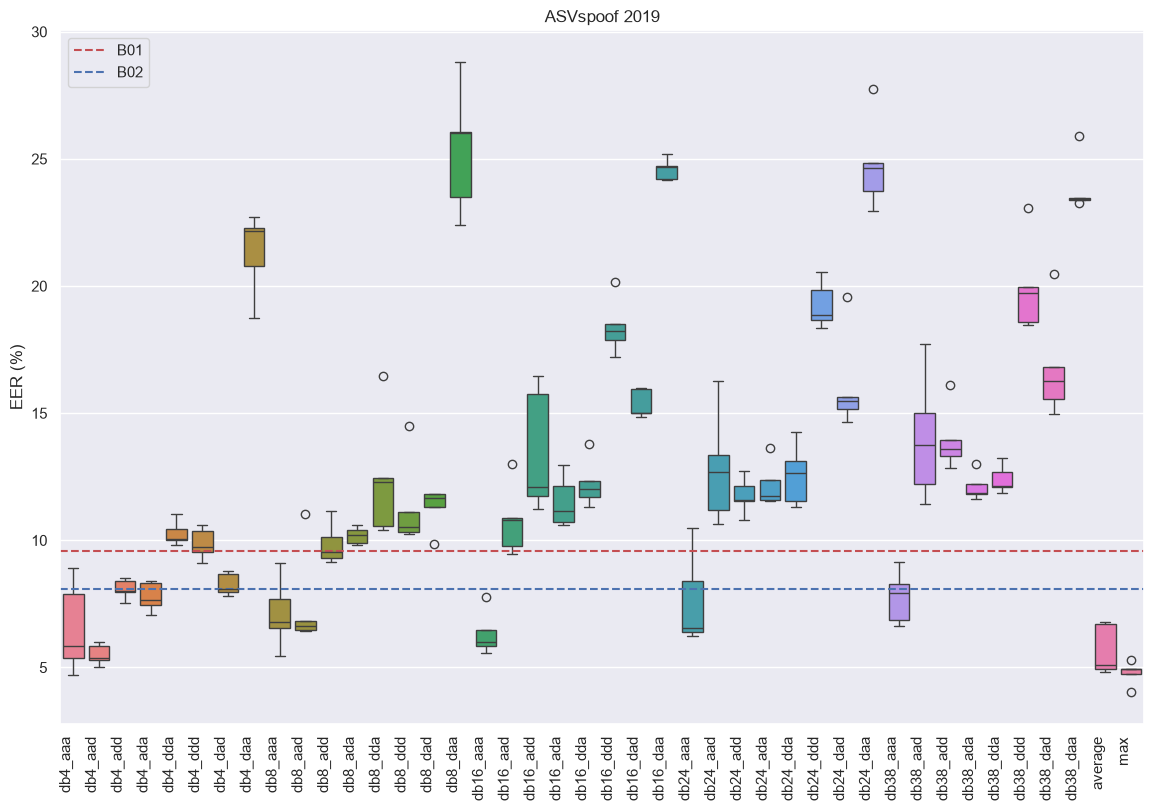

In [143]:
sns.set_theme(rc={'figure.figsize':(11.7,8.27)})
sns.boxplot(data=autorank_input_2019)
plt.title("ASVspoof 2019")

baseline_b01 = 0.0957 * 100
baseline_b02 = 0.0809 * 100

plt.axhline(baseline_b01, color='r', linestyle='--', label='B01')
plt.axhline(baseline_b02, color='b', linestyle='--', label='B02')

plt.xticks(rotation=90, ha='right')

plt.xlabel("")
plt.ylabel("EER (%)")
plt.tight_layout()
plt.legend(loc="upper left")
plt.show()

In [164]:
result_2019 = autorank(autorank_input_2019, alpha=0.05, verbose=False,
                       order='ascending', force_mode='nonparametric',
                       effect_size='akinshin_gamma')
print(result_2019)

Tests for normality and homoscedacity are ignored for test selection, forcing nonparametric tests
          meanrank     median       mad   ci_lower   ci_upper effect_size  \
max            1.6   4.921698  0.175254   4.024541    5.28918         0.0   
db4_aad        2.6   5.353695  0.336666   5.017029   5.995675   -1.085683   
average        3.8   5.087806  0.273716    4.81409    6.77373   -0.487505   
db16_aaa       4.8   5.995675  0.437476   5.558199    7.77693   -2.173765   
db4_aaa        5.6   5.831132  1.140058   4.691074   8.905494   -0.752079   
db8_aaa        6.4   6.772165  0.909434   5.438314   9.098504   -1.905825   
db24_aaa       8.6   6.553036  0.312112   6.240924  10.469186   -4.347232   
db8_aad        8.8   6.648367   0.17682   6.446993  11.050318   -6.615719   
db4_ada        8.8   7.668540  0.585045   7.083495   8.390443   -4.290173   
db38_aaa       9.0   7.927631  1.064048   6.648367    9.14996   -2.658868   
db4_add       10.0   8.021396  0.394383   7.519405   8.

In [167]:
print(result_2019.omnibus)
print(result_2019.posthoc)
print(result_2019.all_normal)
print(result_2019.homogeneity_test)
print(result_2019.homoscedastic)
print(result_2019.pvalue)
print(result_2019.cd)
print(result_2019.effect_size)

friedman
nemenyi
False
levene
True
1.8816215822808753e-21
30.34133997595581
akinshin_gamma


In [166]:
summary_2019 = pd.DataFrame({
    "Mean EER": autorank_input_2019.mean(),
    "Std EER": autorank_input_2019.std(ddof=1),
    "Mean t-DCF": df_2019.groupby("configuration")["min_tdcf"].mean(),
    "Mean Rank": result_2019.rankdf["meanrank"]
})

summary_2019 = summary_2019.sort_values("Mean Rank")

print(summary_2019)

           Mean EER   Std EER  Mean t-DCF  Mean Rank
max        4.786249  0.468957    0.131399        1.6
db4_aad    5.503036  0.402264    0.159138        2.6
average    5.665749  0.990772    0.156798        3.8
db16_aaa   6.332547  0.874059    0.187411        4.8
db4_aaa    6.534126  1.783838    0.182358        5.6
db8_aaa    7.105955  1.370700    0.207026        6.4
db24_aaa   7.614110  1.820077    0.225813        8.6
db4_ada    7.784610  0.556428    0.210359        8.8
db8_aad    7.485557  1.998178    0.218825        8.8
db38_aaa   7.777244  1.035123    0.231805        9.0
db4_add    8.091811  0.398381    0.237741       10.0
db4_dad    8.260012  0.447320    0.232375       10.4
db8_add    9.846947  0.816498    0.282730       14.2
db4_ddd    9.864605  0.610117    0.287187       14.2
db4_dda   10.267763  0.482263    0.300767       15.0
db8_ada   10.189826  0.346384    0.292739       15.6
db16_aad  10.778373  1.391995    0.317809       18.6
db8_ddd   11.343569  1.793113    0.333555     

In [147]:
create_report(result_2019)

The statistical analysis was conducted for 42 populations with 5 paired samples.
The family-wise significance level of the tests is alpha=0.050.
We rejected the null hypothesis that the population is normal for the populations db16_dad (p=0.001) and db24_dad (p=0.001). Therefore, we assume that not all populations are normal.
Because we have more than two populations and the populations and some of them are not normal, we use the non-parametric Friedman test as omnibus test to determine if there are any significant differences between the median values of the populations. We use the post-hoc Nemenyi test to infer which differences are significant. We report the median (MD), the median absolute deviation (MAD) and the mean rank (MR) among all populations over the samples. Differences between populations are significant, if the difference of the mean rank is greater than the critical distance CD=30.341 of the Nemenyi test.
We reject the null hypothesis (p=0.000) of the Friedman test that

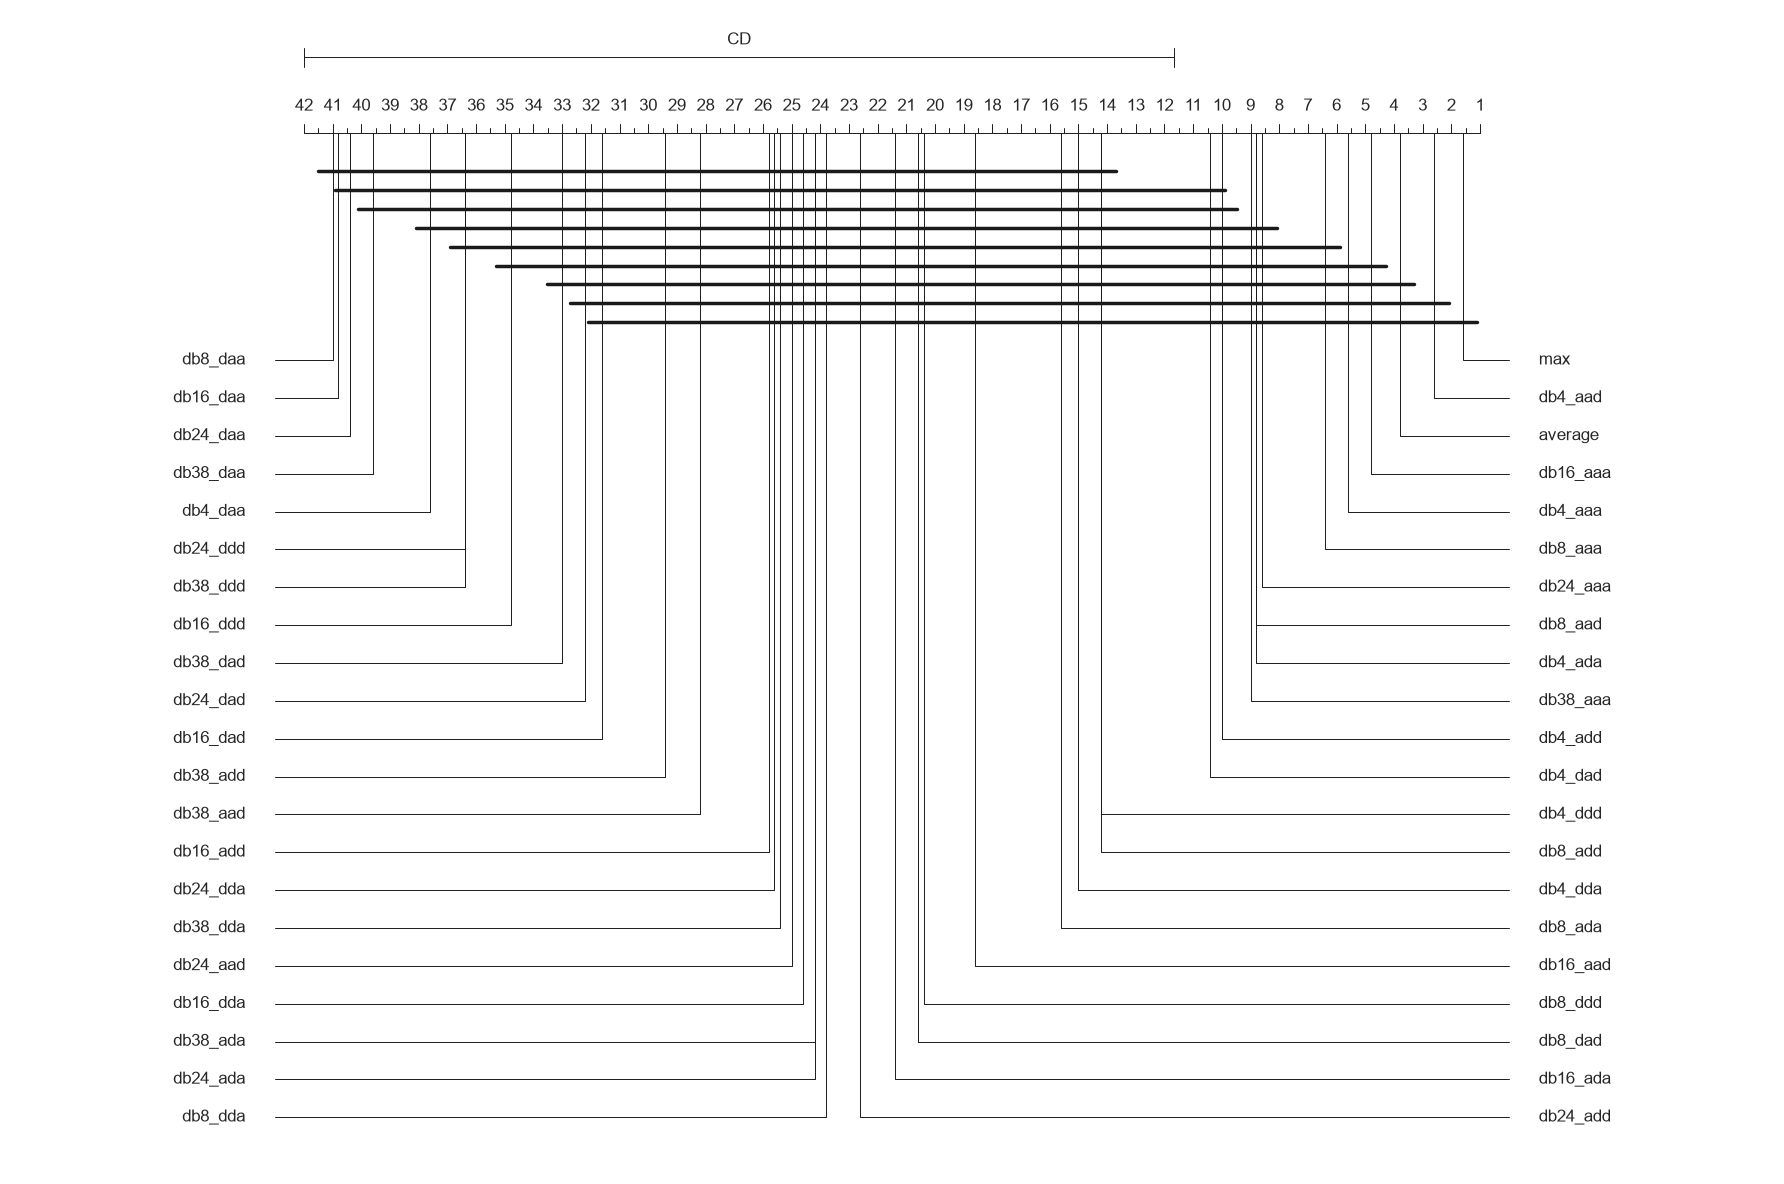

In [ ]:
fig, ax = plt.subplots(figsize=(18, 12))

plot_stats(
    result_2019,
    allow_insignificant=True,
    ax=ax
)

plt.tight_layout()
plt.show()

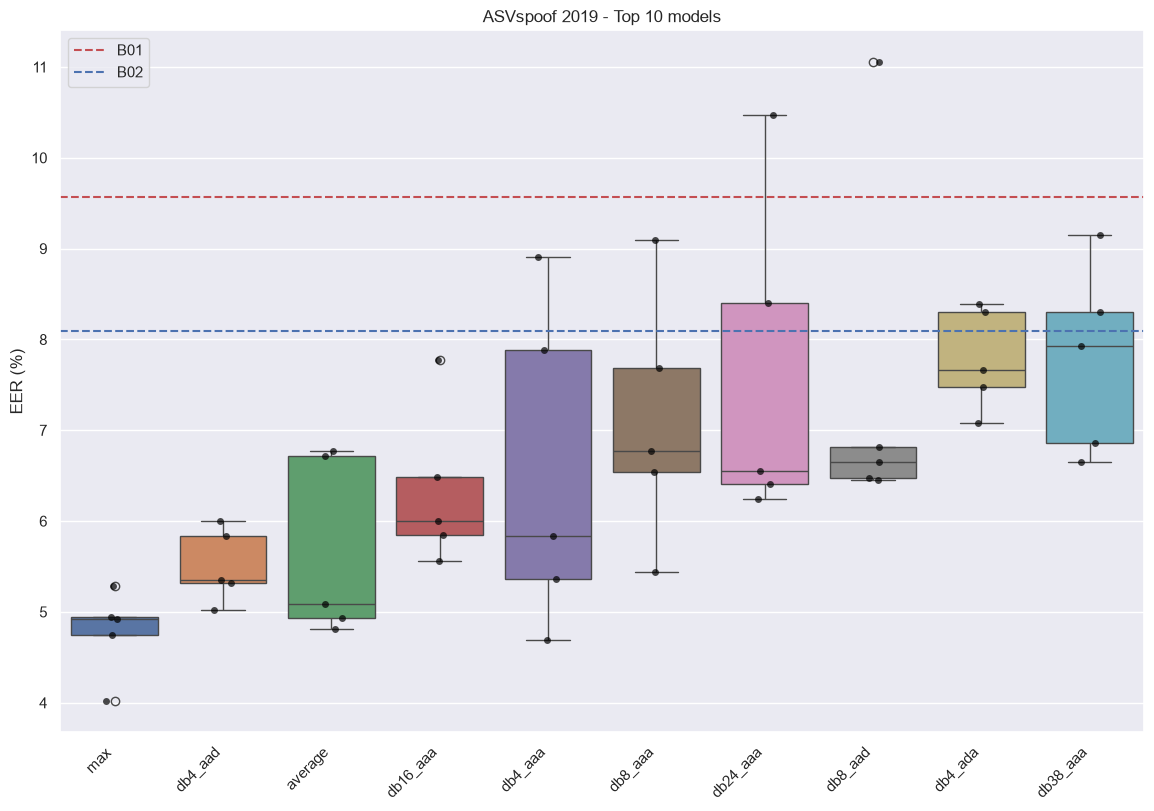

In [149]:
autorank_2019_ranking = result_2019[0]
top_10_results_ranking = autorank_2019_ranking[:10]
top_10_results = autorank_input_2019[top_10_results_ranking.index]

sns.boxplot(data=top_10_results)
sns.stripplot(data=top_10_results, color='black', alpha=0.7)
plt.title("ASVspoof 2019 - Top 10 models")

baseline_b01 = 0.0957 * 100
baseline_b02 = 0.0809 * 100

plt.axhline(baseline_b01, color='r', linestyle='--', label='B01')
plt.axhline(baseline_b02, color='b', linestyle='--', label='B02')

plt.xticks(rotation=45, ha='right')

plt.xlabel("")
plt.ylabel("EER (%)")
plt.tight_layout()
plt.legend(loc="upper left")
plt.show()

In [66]:
bayesian_result_2019 = autorank(
    autorank_input_2019, 
    alpha=0.05, 
    approach='bayesian', 
    rope=0.1,
    verbose=False, 
    order='ascending'
)

          meanrank     median       mad   ci_lower   ci_upper effect_size  \
max            1.6   4.921698  0.175254   4.024541    5.28918         0.0   
average        3.8   5.087806  0.273716    4.81409    6.77373   -0.487505   
db4_aad        2.6   5.353695  0.336666   5.017029   5.995675   -1.085683   
db4_aaa        5.6   5.831132  1.140058   4.691074   8.905494   -0.752079   
db16_aaa       4.8   5.995675  0.437476   5.558199    7.77693   -2.173765   
db24_aaa       8.6   6.553036  0.312112   6.240924  10.469186   -4.347232   
db8_aad        8.8   6.648367   0.17682   6.446993  11.050318   -6.615719   
db8_aaa        6.4   6.772165  0.909434   5.438314   9.098504   -1.905825   
db4_ada        8.8   7.668540  0.585045   7.083495   8.390443   -4.290173   
db38_aaa       9.0   7.927631  1.064048   6.648367    9.14996   -2.658868   
db4_add       10.0   8.021396  0.394383   7.519405   8.521822   -6.851088   
db4_dad       10.4   8.075983  0.273716   7.802267   8.810163   -9.257403   

In [118]:
print(bayesian_result_2019.effect_size)

akinshin_gamma


In [67]:
create_report(bayesian_result_2019)

The statistical analysis was conducted for 42 populations with 5 paired samples.
The family-wise significance level of the tests is alpha=0.050.
We rejected the null hypothesis that the population is normal for the populations db16_dad (p=0.001) and db24_dad (p=0.001). Therefore, we assume that not all populations are normal.
We used a bayesian signed rank test to determine differences between the mean values of the populations and report the median (MD) and the median absolute deviation (MAD) for each population. We distinguish between populations being pair-wise smaller, equal, or larger and make a decision for one of these cases if we estimate that the posterior probability is at least alpha=0.050.
We used the effect size to define the region of practical equivalence (ROPE) around the median dynamically as 0.100*gamma.
We found significant and practically relevant differences between the populations max (MD=4.922+-0.632, MAD=0.175), average (MD=5.088+-0.980, MAD=0.274), db4_aad (MD=

## ASVspoof 2019 - Wavelets vs Nodes

In [195]:
df = autorank_input_2019.copy()

df = df.loc[:, ~df.columns.isin(["max", "average"])]

df.columns = pd.MultiIndex.from_tuples(
    [col.split("_", 1) for col in df.columns],
    names=["Wavelet", "Node"]
)

mean_eer_wave = df.mean(axis=0).unstack("Node")
mean_eer_wave = mean_eer_wave[['aaa', 'aad', 'add', 'ada', 'dda', 'ddd', 'dad', 'daa']]

mean_eer_wave = mean_eer_wave.sort_index(
    key=lambda idx: idx.map(lambda x: int(x.replace("db", "")))
)

mean_eer_wave.T

Wavelet,db4,db8,db16,db24,db38
Node,,,,,
aaa,6.534126,7.105955,6.332547,7.614110,7.777244
aad,5.503036,7.485557,10.778373,12.832092,14.025846
add,8.091811,9.846947,13.464201,11.763026,13.955432
ada,7.784610,10.189826,11.516417,12.174333,12.113896
dda,10.267763,12.434783,12.234770,12.582246,12.396651
ddd,9.864605,11.343569,18.400945,19.251664,19.951263
dad,8.260012,11.298071,15.358132,16.105998,16.818030
daa,21.343359,25.364505,24.595744,24.784263,23.888622


### Wavelets

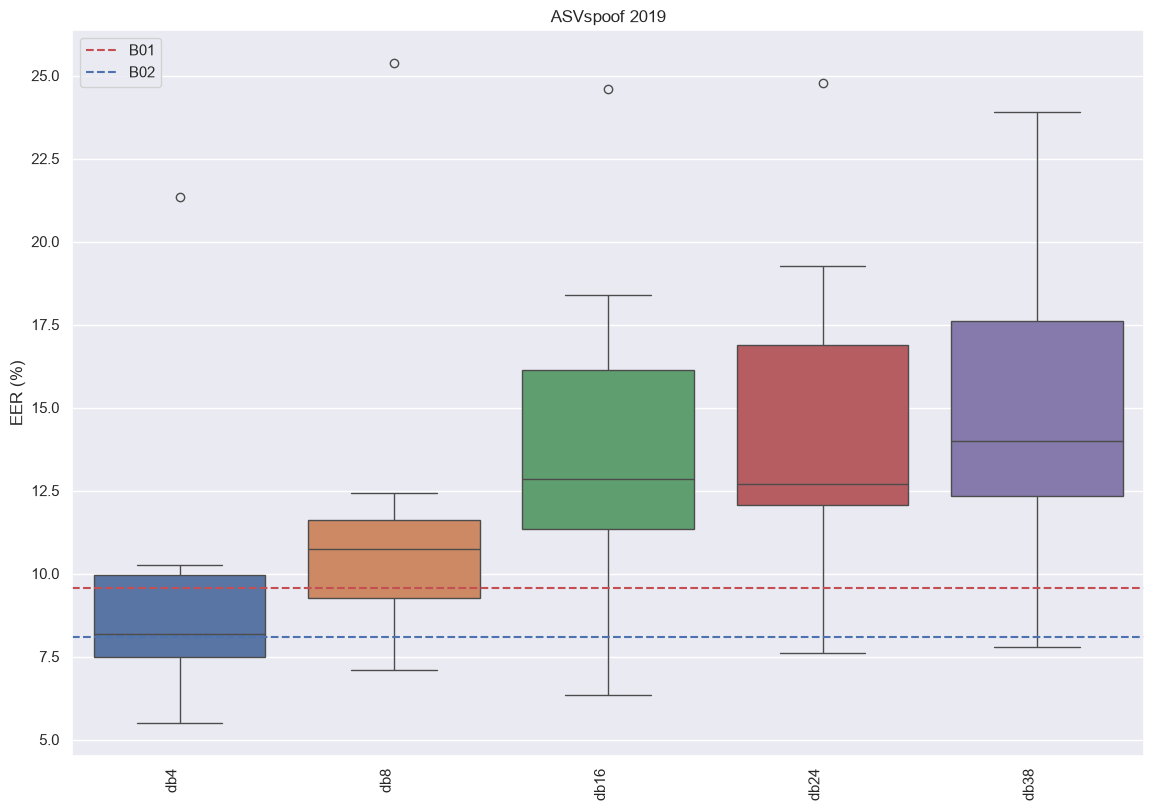

In [196]:
sns.set_theme(rc={'figure.figsize':(11.7,8.27)})
sns.boxplot(data=mean_eer_wave.T)
plt.title("ASVspoof 2019")

baseline_b01 = 0.0957 * 100
baseline_b02 = 0.0809 * 100

plt.axhline(baseline_b01, color='r', linestyle='--', label='B01')
plt.axhline(baseline_b02, color='b', linestyle='--', label='B02')

plt.xticks(rotation=90, ha='right')

plt.xlabel("")
plt.ylabel("EER (%)")
plt.tight_layout()
plt.legend(loc="upper left")
plt.show()

In [197]:
result_2019_wavelet = autorank(mean_eer_wave.T, alpha=0.05, verbose=False,
                       order='ascending', force_mode='nonparametric',
                       effect_size='akinshin_gamma')
print(result_2019_wavelet)

Tests for normality and homoscedacity are ignored for test selection, forcing nonparametric tests
      meanrank     median       mad  ci_lower   ci_upper effect_size  \
db4      1.125   8.175912  1.665239  5.503036  21.343359         0.0   
db8      2.750  10.743948  1.293918  7.105955  25.364505   -1.161573   
db16     2.750  12.849485  2.289879  6.332547  24.595744   -1.574511   
db24     4.125  12.707169  2.171486   7.61411  24.784263   -1.579487   
db38     4.250  13.990639  2.352067  7.777244  23.888622   -1.924617   

       magnitude effect_size_above magnitude_above  
db4   negligible               0.0      negligible  
db8        large         -1.161573           large  
db16       large         -0.763609          medium  
db24       large          0.043017      negligible  
db38       large         -0.382443           small  
RankResult(rankdf=
      meanrank     median       mad  ci_lower   ci_upper effect_size  \
db4      1.125   8.175912  1.665239  5.503036  21.343359    

In [198]:
summary_2019_wavelet = pd.DataFrame({
    "Mean EER": mean_eer_wave.T.mean(),
    "Std EER": mean_eer_wave.T.std(ddof=1),
    "Mean t-DCF": df_2019.groupby("wavelet")["min_tdcf"].mean(),
    "Mean Rank": result_2019_wavelet.rankdf["meanrank"]
})

summary_2019_wavelet = summary_2019_wavelet.sort_values("Mean Rank")

print(summary_2019_wavelet)

       Mean EER   Std EER  Mean t-DCF  Mean Rank
db4    9.706165  4.955268    0.258338      1.125
db16  14.085141  5.505382    0.370301      2.750
db8   11.883652  5.755228    0.319902      2.750
db24  14.638466  5.312319    0.386119      4.125
db38  15.115873  5.014775    0.395715      4.250


In [199]:
create_report(result_2019_wavelet)

The statistical analysis was conducted for 5 populations with 8 paired samples.
The family-wise significance level of the tests is alpha=0.050.
We rejected the null hypothesis that the population is normal for the populations db4 (p=0.004) and db8 (p=0.004). Therefore, we assume that not all populations are normal.
Because we have more than two populations and the populations and some of them are not normal, we use the non-parametric Friedman test as omnibus test to determine if there are any significant differences between the median values of the populations. We use the post-hoc Nemenyi test to infer which differences are significant. We report the median (MD), the median absolute deviation (MAD) and the mean rank (MR) among all populations over the samples. Differences between populations are significant, if the difference of the mean rank is greater than the critical distance CD=2.156 of the Nemenyi test.
We reject the null hypothesis (p=0.000) of the Friedman test that there is no

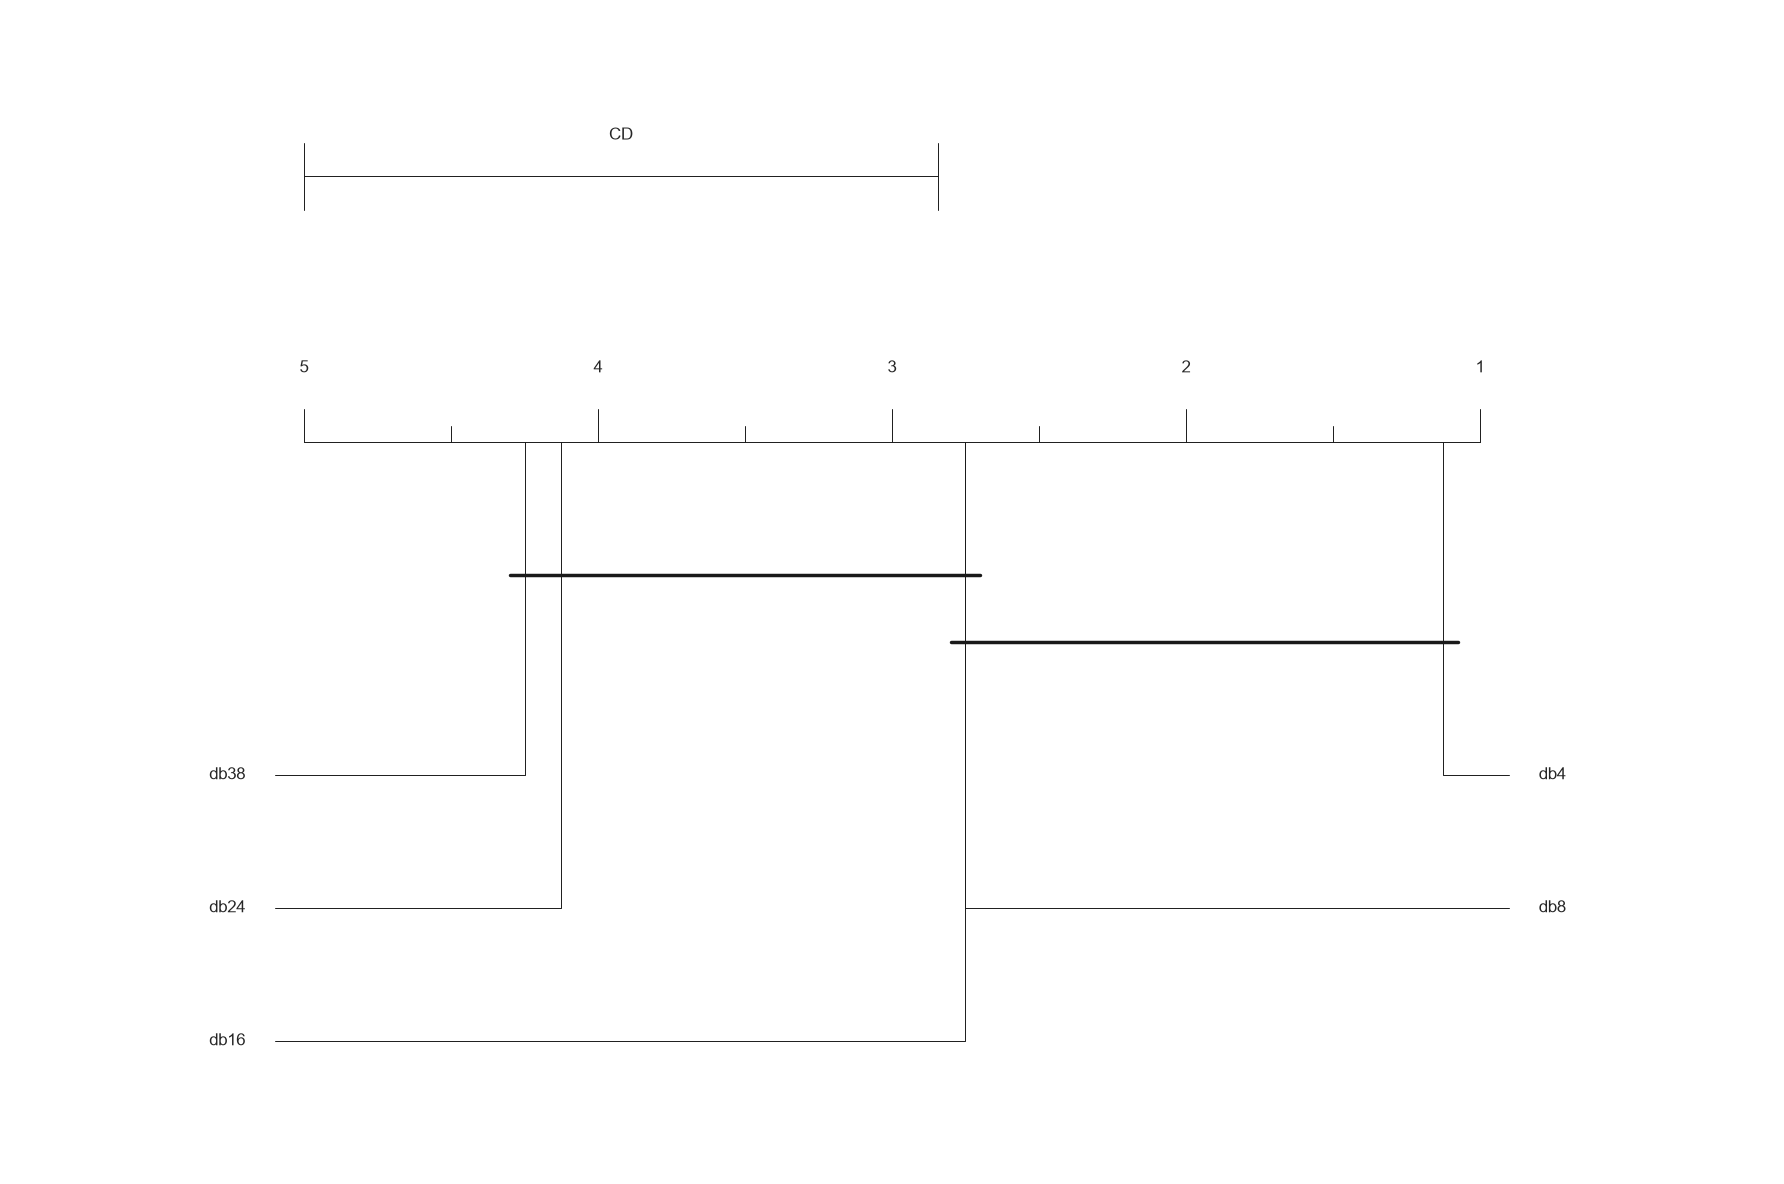

In [200]:
fig, ax = plt.subplots(figsize=(18, 12))

plot_stats(
    result_2019_wavelet,
    allow_insignificant=True,
    ax=ax
)

plt.tight_layout()
plt.show()

### Nodes

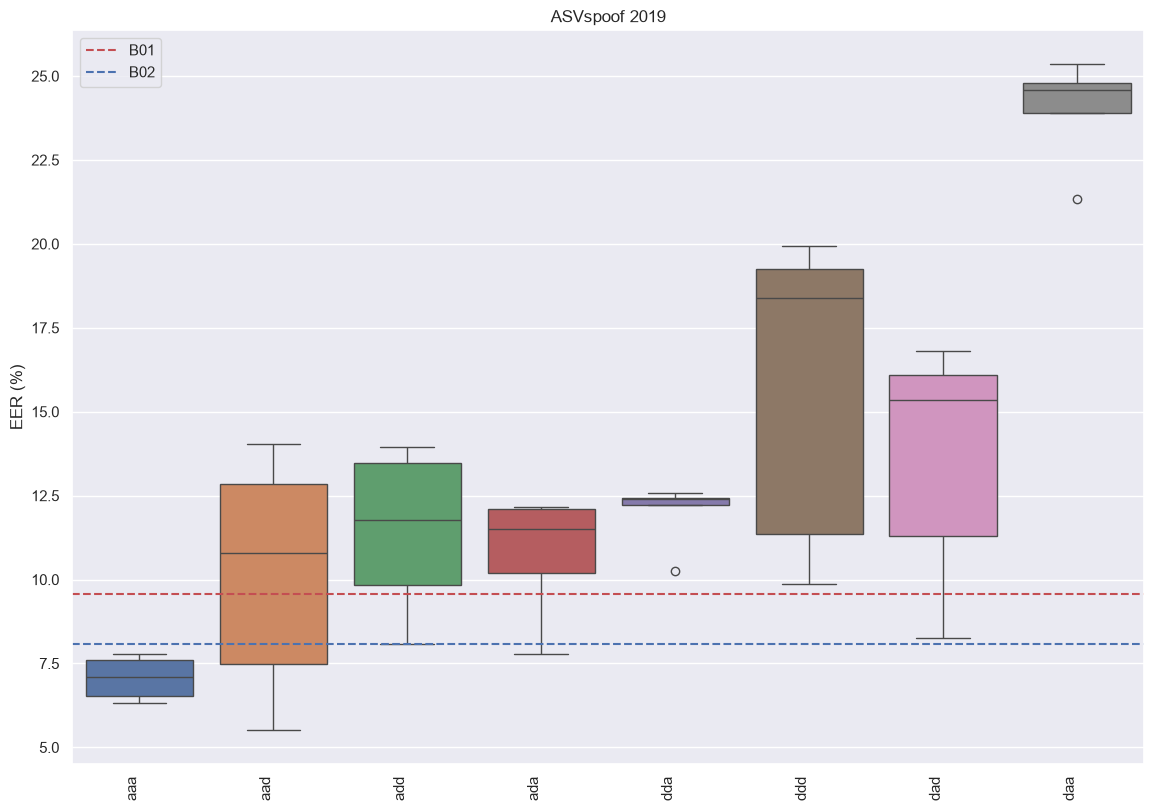

In [201]:
sns.set_theme(rc={'figure.figsize':(11.7,8.27)})
sns.boxplot(data=mean_eer_wave)
plt.title("ASVspoof 2019")

baseline_b01 = 0.0957 * 100
baseline_b02 = 0.0809 * 100

plt.axhline(baseline_b01, color='r', linestyle='--', label='B01')
plt.axhline(baseline_b02, color='b', linestyle='--', label='B02')

plt.xticks(rotation=90, ha='right')

plt.xlabel("")
plt.ylabel("EER (%)")
plt.tight_layout()
plt.legend(loc="upper left")
plt.show()

In [202]:
result_2019_nodes = autorank(mean_eer_wave, alpha=0.05, verbose=False,
                       order='ascending', force_mode='nonparametric',
                       effect_size='akinshin_gamma')
print(result_2019_nodes)

Tests for normality and homoscedacity are ignored for test selection, forcing nonparametric tests
     meanrank     median       mad   ci_lower   ci_upper effect_size  \
aaa       1.2   7.105955  0.571829   6.332547   7.777244         0.0   
aad       3.0  10.778373  3.247474   5.503036  14.025846   -1.062348   
ada       3.0  11.516417  0.657916    7.78461  12.174333   -4.826292   
add       3.6  11.763026  1.916078   8.091811  13.955432   -2.221589   
dda       5.0  12.396651  0.161881  10.267763  12.582246   -8.491746   
dad       5.6  15.358132  1.459899   8.260012   16.81803   -5.020451   
ddd       6.6  18.400945  1.550319   9.864605  19.951263    -6.52015   
daa       8.0  24.595744  0.707122  21.343359  25.364505  -18.345106   

      magnitude effect_size_above magnitude_above  
aaa  negligible               0.0      negligible  
aad       large         -1.062348           large  
ada       large         -0.212468           small  
add       large         -0.116114      neglig

In [205]:
summary_2019_nodes = pd.DataFrame({
    "Mean EER": mean_eer_wave.mean(),
    "Std EER": mean_eer_wave.std(ddof=1),
    "Mean t-DCF": df_2019.groupby("node")["min_tdcf"].mean(),
    "Mean Rank": result_2019_nodes.rankdf["meanrank"]
})

summary_2019_nodes = summary_2019_nodes.sort_values("Mean Rank")

print(summary_2019_nodes)

      Mean EER   Std EER  Mean t-DCF  Mean Rank
aaa   7.072796  0.638064    0.206883        1.2
aad  10.124981  3.581238    0.297697        3.0
ada  10.755816  1.842790    0.302087        3.0
add  11.424283  2.463538    0.330772        3.6
dda  11.983243  0.966920    0.338281        5.0
dad  13.568049  3.658415    0.373417        5.6
ddd  15.762409  4.769526    0.398345        6.6
daa  23.995299  1.573363    0.521119        8.0


In [206]:
create_report(result_2019_nodes)

The statistical analysis was conducted for 8 populations with 5 paired samples.
The family-wise significance level of the tests is alpha=0.050.
We rejected the null hypothesis that the population is normal for the population dda (p=0.005). Therefore, we assume that not all populations are normal.
Because we have more than two populations and the populations and one of them is not normal, we use the non-parametric Friedman test as omnibus test to determine if there are any significant differences between the median values of the populations. We use the post-hoc Nemenyi test to infer which differences are significant. We report the median (MD), the median absolute deviation (MAD) and the mean rank (MR) among all populations over the samples. Differences between populations are significant, if the difference of the mean rank is greater than the critical distance CD=4.695 of the Nemenyi test.
We reject the null hypothesis (p=0.000) of the Friedman test that there is no difference in the ce

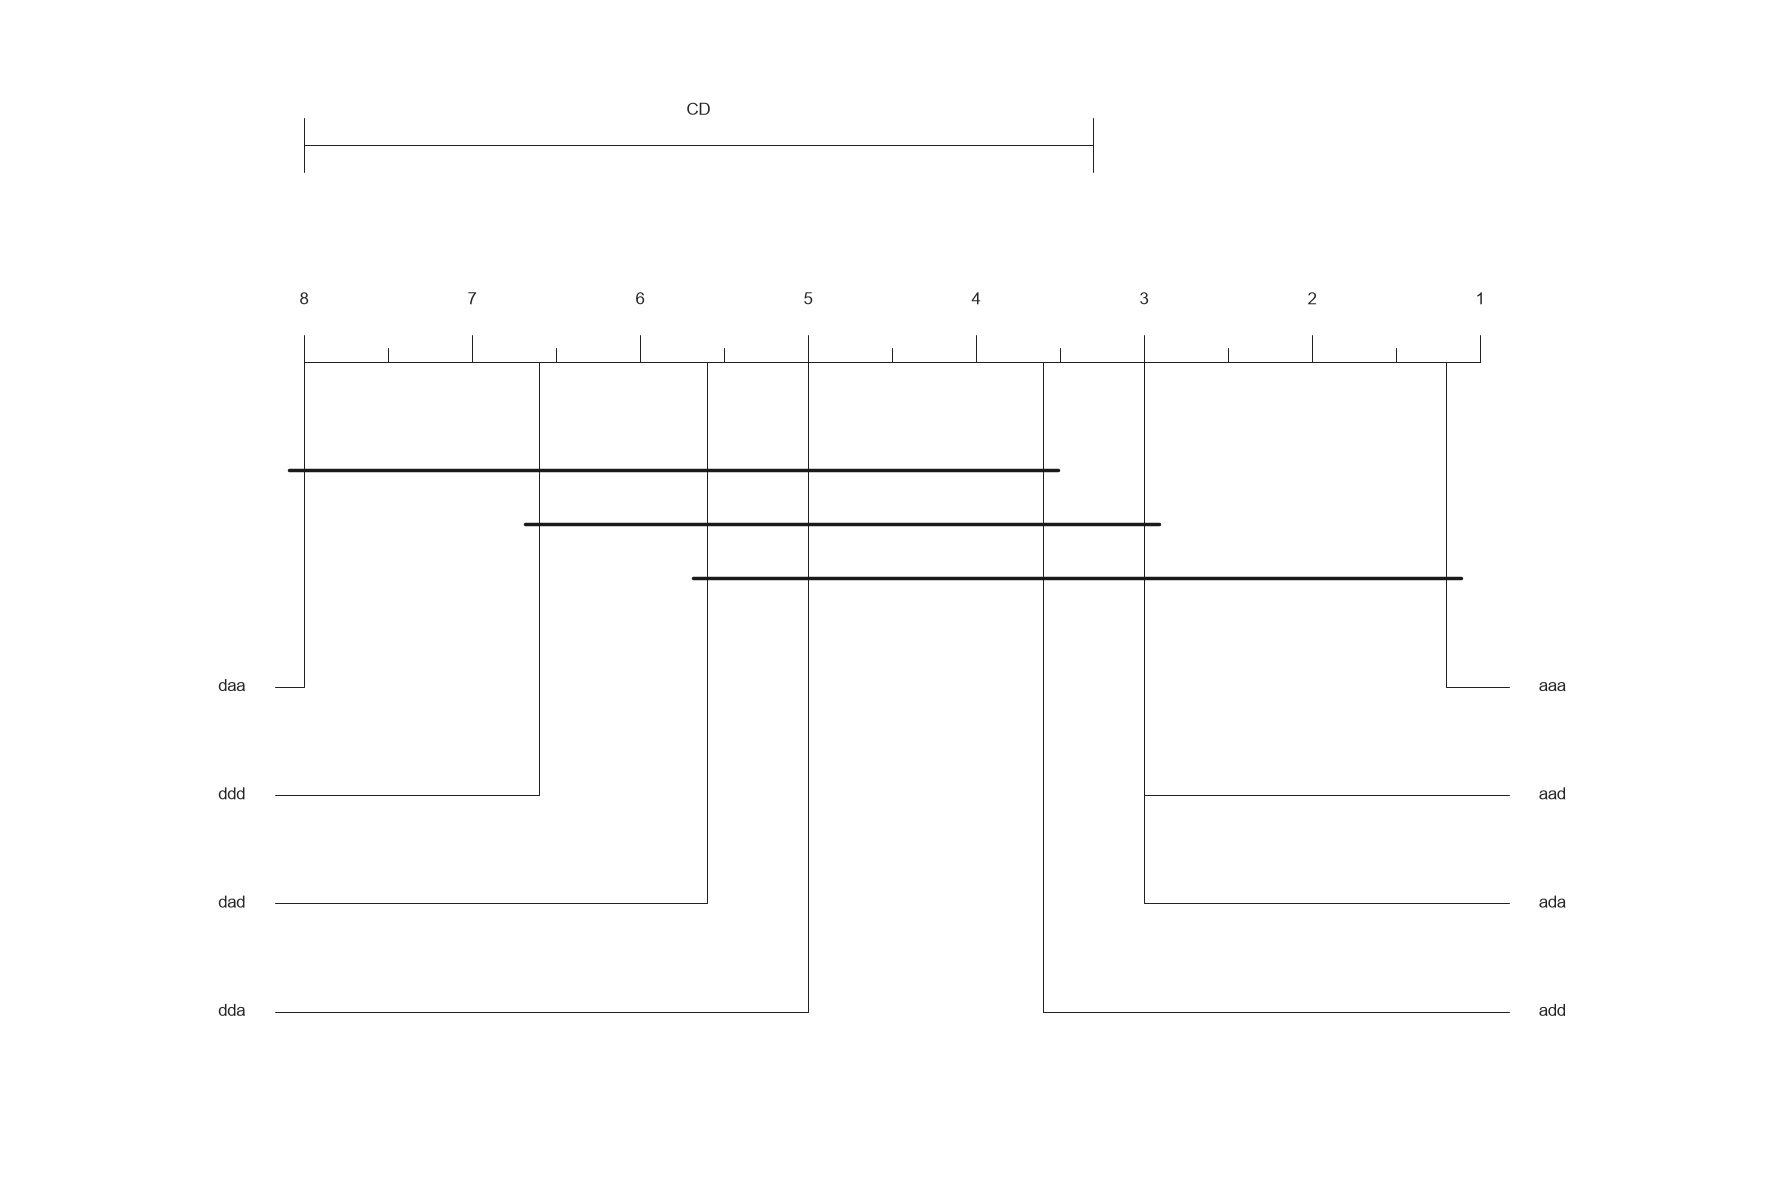

In [207]:
fig, ax = plt.subplots(figsize=(18, 12))

plot_stats(
    result_2019_nodes,
    allow_insignificant=True,
    ax=ax
)

plt.tight_layout()
plt.show()

## ASVspoof 2021 - wavelet_nodes

In [219]:
df_2021["configuration"] = np.where(
    df_2021["pooling"] == "wavelet",
    df_2021["wavelet"] + "_" + df_2021["node"],
    df_2021["pooling"]
)

autorank_input_2021 = df_2021.pivot_table(
    index="seed",
    columns="configuration",
    values="eer",
    aggfunc="mean"
)

autorank_input_2021 = autorank_input_2021[columns]
autorank_input_2021

configuration,db4_aaa,db4_aad,db4_add,db4_ada,db4_dda,db4_ddd,db4_dad,db4_daa,db8_aaa,db8_aad,...,db38_aaa,db38_aad,db38_add,db38_ada,db38_dda,db38_ddd,db38_dad,db38_daa,average,max
seed,,,,,,,,,,,,,,,,,,,,,
42,24.160193,13.765332,18.068423,19.146854,35.068434,29.801752,30.105231,42.206742,24.165355,13.944875,...,23.953921,19.039016,20.013544,24.100345,42.466780,48.276637,47.718282,48.454341,24.262869,23.363368
52,24.263789,15.299135,18.590031,18.128271,35.887746,31.667296,31.264770,40.845480,24.134076,13.732828,...,24.474303,16.448044,20.378097,25.574607,41.865903,47.366199,46.439355,47.800311,23.845776,24.170823
62,23.547459,13.646251,18.323606,20.398132,34.798379,27.059193,30.434521,41.106131,24.083940,15.559173,...,24.317248,18.241884,18.811789,26.766344,36.695509,48.243213,47.875644,49.322870,24.555718,23.195376
72,23.932353,13.782964,18.545363,19.966166,32.229587,23.699352,29.096359,40.923266,23.802335,13.938793,...,24.300842,21.412166,18.247353,24.245544,42.580700,47.073350,47.947348,47.316676,23.460882,23.634343
82,23.823902,16.431945,17.401924,17.656493,29.384353,26.588028,30.988327,41.338826,24.040805,15.792174,...,24.208797,15.857490,18.919321,23.233962,40.207856,48.645433,46.216678,49.475376,23.872813,23.476981


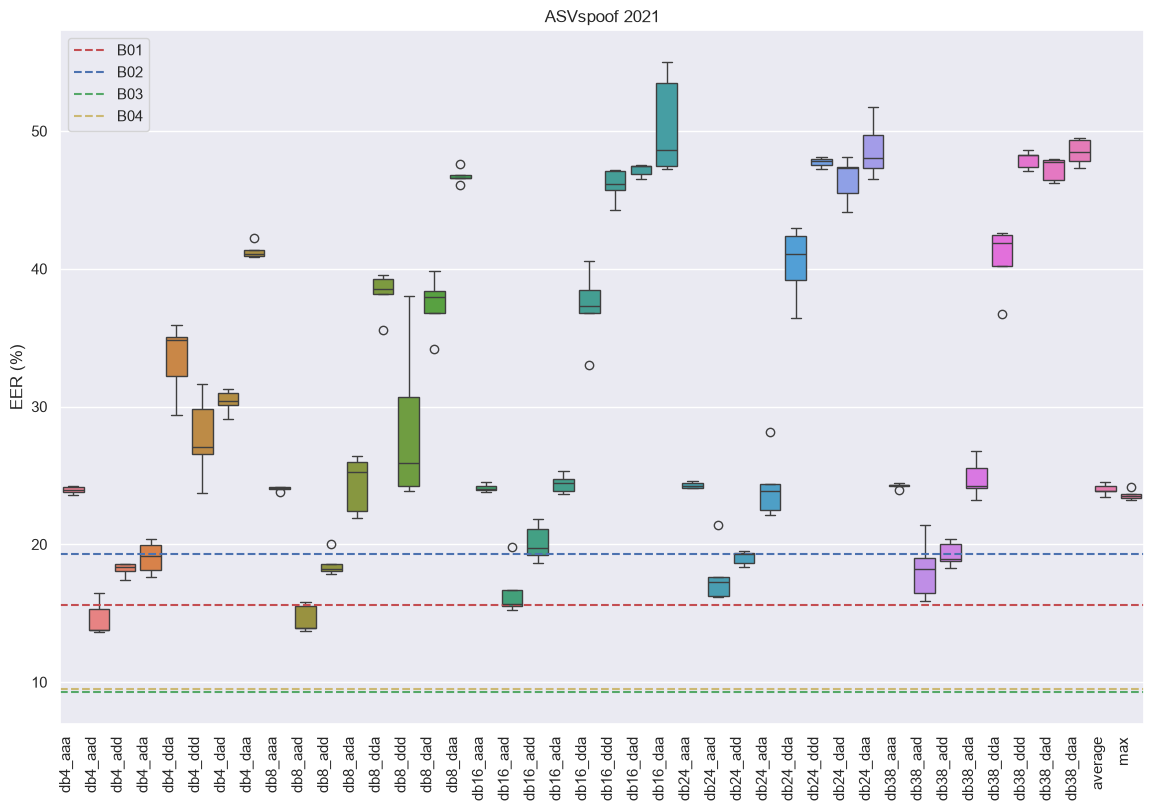

In [151]:
sns.set_theme(rc={'figure.figsize':(11.7,8.27)})
sns.boxplot(data=autorank_input_2021)
plt.title("ASVspoof 2021")

baseline_b03 = 9.26
baseline_b04 = 9.50
baseline_b01 = 15.62
baseline_b02 = 19.30

plt.axhline(baseline_b01, color='r', linestyle='--', label='B01')
plt.axhline(baseline_b02, color='b', linestyle='--', label='B02')
plt.axhline(baseline_b03, color='g', linestyle='--', label='B03')
plt.axhline(baseline_b04, color='y', linestyle='--', label='B04')

plt.xticks(rotation=90, ha='right')

plt.xlabel("")
plt.ylabel("EER (%)")
plt.tight_layout()
plt.legend(loc="upper left")
plt.show()

In [160]:
result_2021 = autorank(autorank_input_2021, alpha=0.05, verbose=False,
                       order='ascending', force_mode='nonparametric',
                       effect_size='akinshin_gamma')
print(result_2021)

Tests for normality and homoscedacity are ignored for test selection, forcing nonparametric tests
          meanrank     median       mad   ci_lower   ci_upper effect_size  \
db4_aad        1.6  13.782964  0.136714  10.035482  19.134769         0.0   
db8_aad        1.6  13.944875  0.212047  10.933358  18.253779   -0.612141   
db16_aad       4.4  15.640588  0.407688   9.638525  23.515168   -4.120785   
db38_aad       5.4  18.241884   1.79384  10.060193  26.339247   -2.364173   
db24_aad       5.4  17.267662  1.014647    9.84121  25.648098   -3.246641   
db4_add        6.0  18.323606  0.255182  16.402533  19.969206   -14.96112   
db8_add        6.8  18.225785  0.347228  15.406529  21.688696  -11.356387   
db4_ada        8.0  19.146854  1.018583  14.762096   23.35627   -4.978487   
db24_add       8.2  19.271711  0.221758   17.19801  20.874666  -20.097147   
db38_add       9.0  18.919321  0.671968  16.004454  22.543588     -7.1448   
db16_add       9.6  19.710677  1.045926    15.1895  25.

In [161]:
print(result_2021.omnibus)
print(result_2021.posthoc)
print(result_2021.all_normal)
print(result_2021.homogeneity_test)
print(result_2021.homoscedastic)
print(result_2021.pvalue)
print(result_2021.cd)
print(result_2021.effect_size)

friedman
nemenyi
True
bartlett
False
1.8811145381829463e-22
30.34133997595581
akinshin_gamma


In [162]:
summary_2021 = pd.DataFrame({
    "Mean EER": autorank_input_2021.mean(),
    "Std EER": autorank_input_2021.std(ddof=1),
    "Mean t-DCF": df_2021.groupby("configuration")["min_tdcf"].mean(),
    "Mean Rank": result_2021.rankdf["meanrank"]
})

summary_2021 = summary_2021.sort_values("Mean Rank")

print(summary_2021)

           Mean EER   Std EER  Mean t-DCF  Mean Rank
db8_aad   14.593569  0.994919    0.405857        1.6
db4_aad   14.585125  1.236685    0.401882        1.6
db16_aad  16.576846  1.885976    0.468533        4.4
db38_aad  18.199720  2.212488    0.510018        5.4
db24_aad  17.744654  2.148316    0.502697        5.4
db4_add   18.185870  0.484747    0.527035        6.0
db8_add   18.547612  0.853810    0.537794        6.8
db4_ada   19.059183  1.168035    0.539341        8.0
db24_add  19.036338  0.499695    0.550720        8.2
db38_add  19.274021  0.888734    0.552059        9.0
db16_add  20.117804  1.339613    0.583043        9.6
max       23.568178  0.373097    0.623883       13.6
db4_aaa   23.945539  0.283194    0.617680       15.8
average   23.999612  0.420872    0.629140       16.0
db24_ada  24.203022  2.384789    0.698372       16.4
db8_aaa   24.045302  0.143910    0.622374       16.8
db16_aaa  24.125194  0.286217    0.621177       18.0
db8_ada   24.399450  2.102198    0.725283     

In [163]:
create_report(result_2021)

The statistical analysis was conducted for 42 populations with 5 paired samples.
The family-wise significance level of the tests is alpha=0.050.
We failed to reject the null hypothesis that the population is normal for all populations (minimal observed p-value=0.050). Therefore, we assume that all populations are normal.
We applied Bartlett's test for homogeneity and reject the null hypothesis (p=0.000) that thedata is homoscedastic. Thus, we assume that our data is heteroscedastic.
Because we have more than two populations and the populations are normal but heteroscedastic, we use the non-parametric Friedman test as omnibus test to determine if there are any significant differences between the mean values of the populations. We use the post-hoc Nemenyi test to infer which differences are significant. We report the mean value (M), the standard deviation (SD) and the mean rank (MR) among all populations over the samples. Differences between populations are significant, if the difference

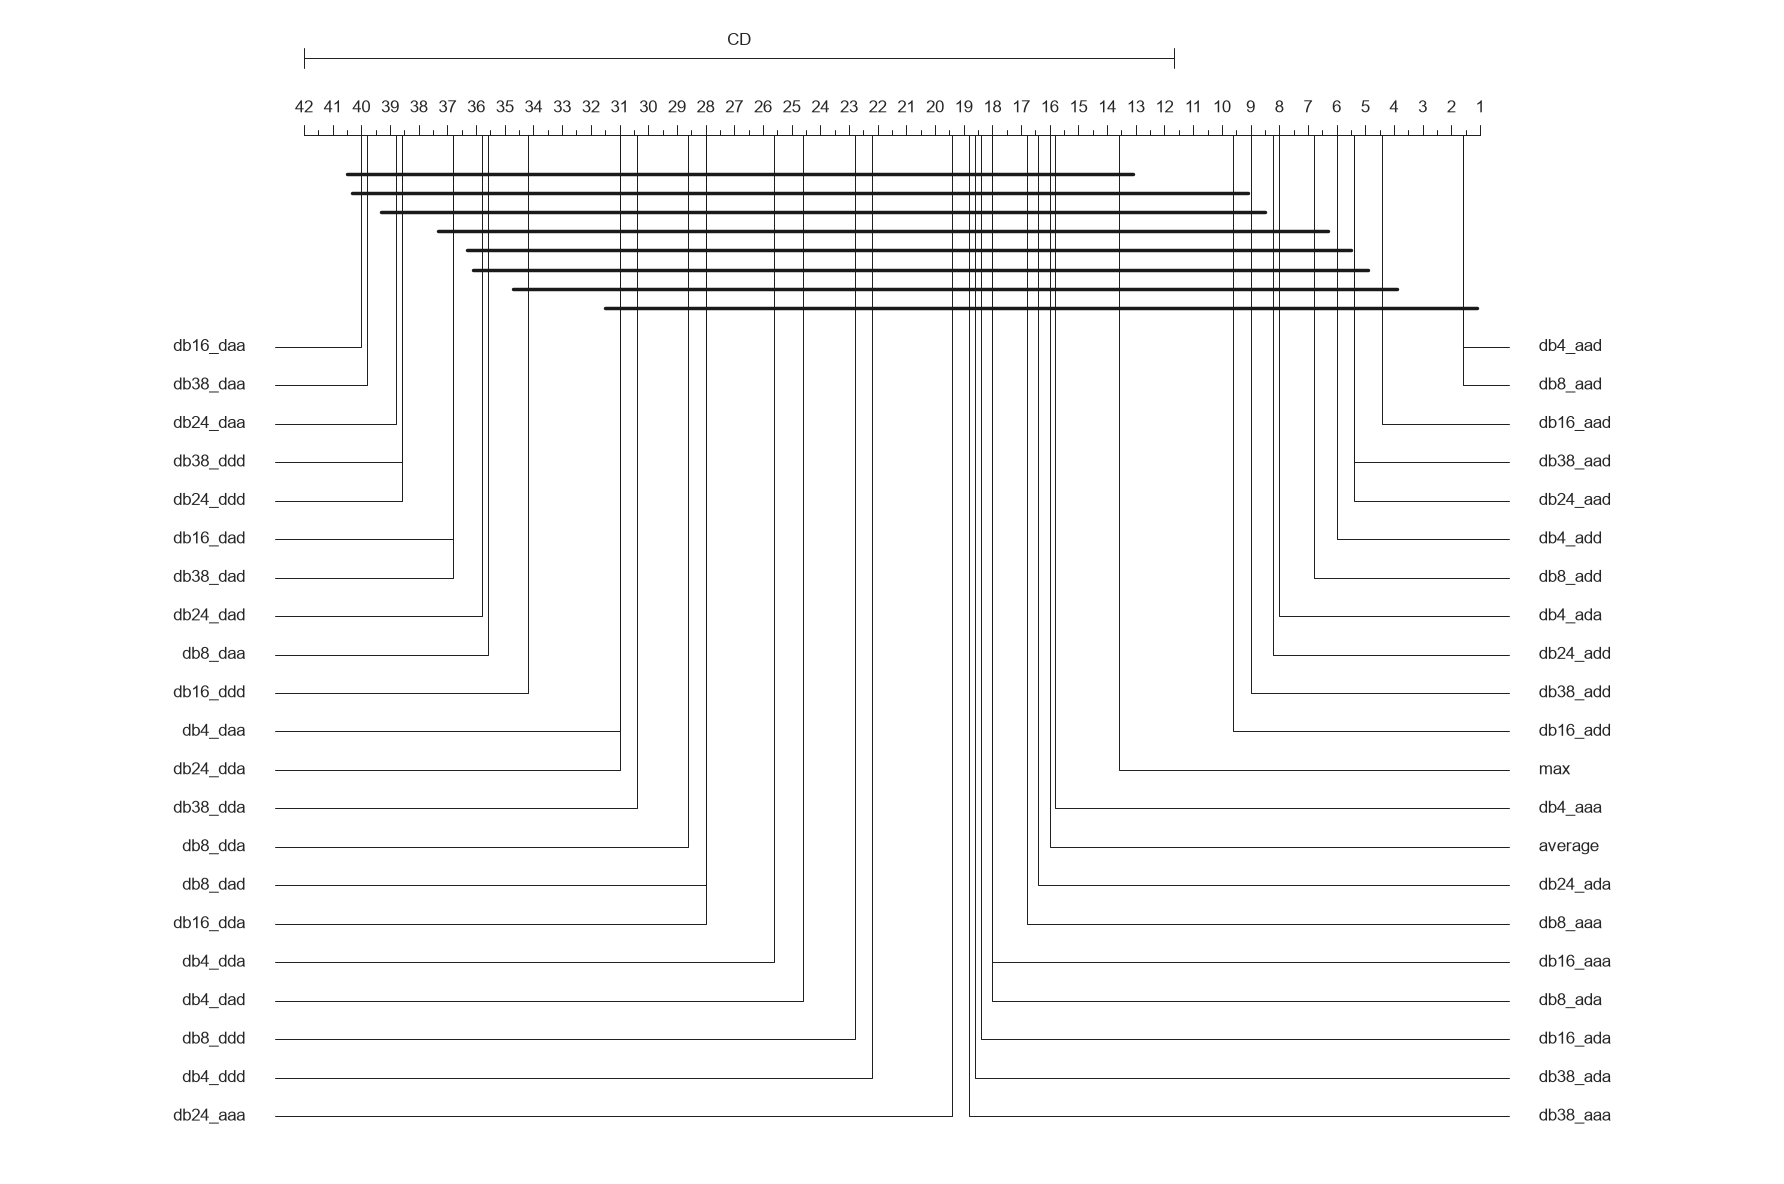

In [156]:
fig, ax = plt.subplots(figsize=(18, 12))

plot_stats(
    result_2021,
    allow_insignificant=True,
    ax=ax
)

plt.tight_layout()
plt.show()

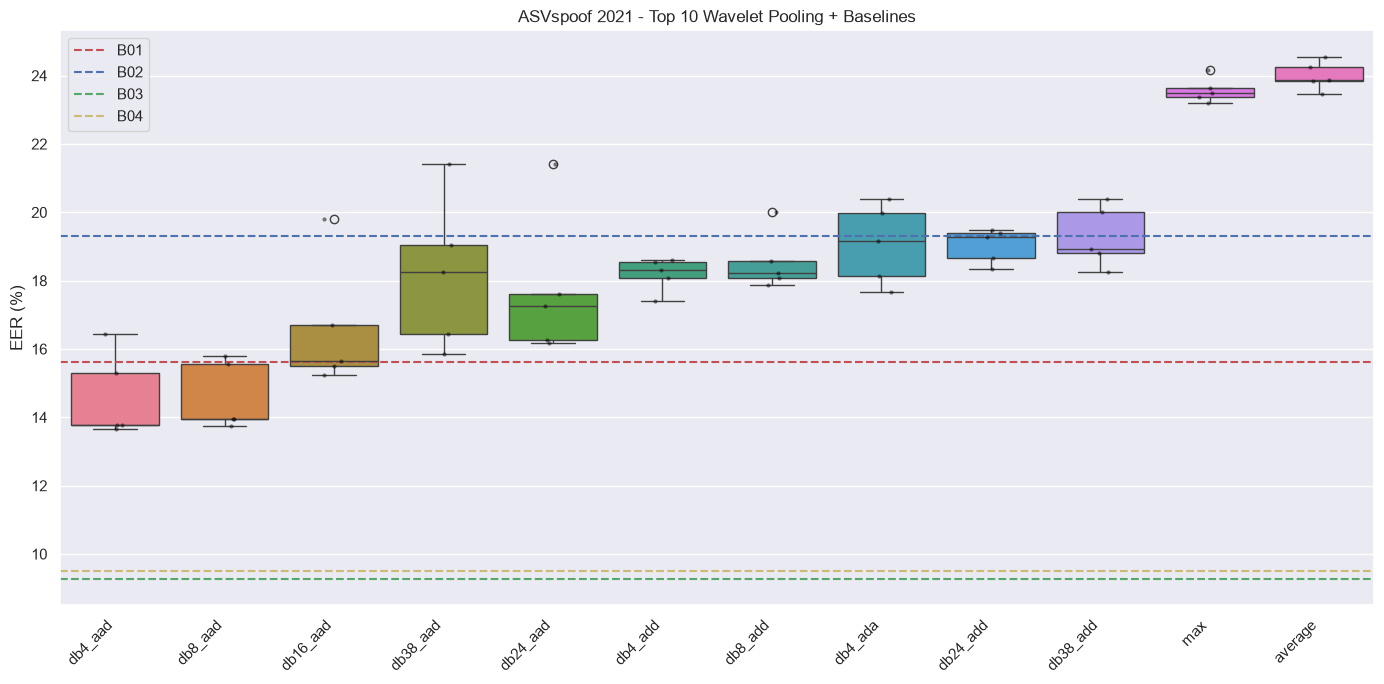

In [ ]:
autorank_2021_ranking = result_2021[0]

top_10_results_ranking = autorank_2021_ranking[:10]

top_10_results = autorank_input_2021[
    top_10_results_ranking.index
].copy()

# Adicionar Max e Average Pooling
top_10_results["max"] = autorank_input_2021["max"]
top_10_results["average"] = autorank_input_2021["average"]

plt.figure(figsize=(14, 7))

sns.boxplot(data=top_10_results)
sns.stripplot(
    data=top_10_results,
    color="black",
    alpha=0.5,
    size=3
)

plt.title("ASVspoof 2021 - Top 10 Wavelet Pooling + Baselines")

baseline_b03 = 9.26
baseline_b04 = 9.50
baseline_b01 = 15.62
baseline_b02 = 19.30

plt.axhline(baseline_b01, color="r", linestyle="--", label="B01")
plt.axhline(baseline_b02, color="b", linestyle="--", label="B02")
plt.axhline(baseline_b03, color="g", linestyle="--", label="B03")
plt.axhline(baseline_b04, color="y", linestyle="--", label="B04")

plt.xticks(rotation=45, ha="right")

plt.xlabel("")
plt.ylabel("EER (%)")

plt.legend(loc="upper left")
plt.tight_layout()

plt.show()

In [74]:
bayesian_result_2021 = autorank(
    autorank_input_2021, 
    alpha=0.05, 
    approach='bayesian', 
    rope=0.1,
    verbose=False, 
    order='ascending'
)

          meanrank       mean       std   ci_lower   ci_upper effect_size  \
db4_aad        1.6  14.585125  1.236685   2.765166  26.405084         0.0   
db8_aad        1.6  14.593569  0.994919   5.084353  24.102784   -0.007523   
db16_aad       4.4  16.576846  1.885976  -1.448892  34.602584   -1.248943   
db24_aad       5.4  17.744654  2.148316   -2.78847  38.277778   -1.802556   
db4_add        6.0  18.185870  0.484747  13.552766  22.818973    -3.83365   
db38_aad       5.4  18.199720  2.212488  -2.946746  39.346185   -2.016764   
db8_add        6.8  18.547612  0.853810  10.387087  26.708137    -3.72893   
db24_add       8.2  19.036338  0.499695  14.260367  23.812309   -4.719489   
db4_ada        8.0  19.059183  1.168035   7.895363  30.223003   -3.719547   
db38_add       9.0  19.274021  0.888734  10.779696  27.768346   -4.354244   
db16_add       9.6  20.117804  1.339613   7.314085  32.921523   -4.291638   
max           13.6  23.568178  0.373097  20.002202  27.134154   -9.834765   

In [75]:
create_report(bayesian_result_2021)

The statistical analysis was conducted for 42 populations with 5 paired samples.
The family-wise significance level of the tests is alpha=0.050.
We failed to reject the null hypothesis that the population is normal for all populations (minimal observed p-value=0.050). Therefore, we assume that all populations are normal.
We used a bayesian signed rank test to determine differences between the mean values of the populations and report the mean value (M) and the standard deviation (SD) for each population. We distinguish between populations being pair-wise smaller, equal, or larger and make a decision for one of these cases if we estimate that the posterior probability is at least alpha=0.050.
We used the effect size to define the region of practical equivalence (ROPE) around the mean value dynamically as 0.100*d.
We found significant and practically relevant differences between the populations db4_aad (M=14.585+-11.820, SD=1.237), db8_aad (M=14.594+-9.509, SD=0.995), db16_aad (M=16.577+

## ASVspoof 2021 - Wavelets vs Nodes

In [220]:
df_wave_2021 = autorank_input_2021.copy()

df_wave_2021 = df_wave_2021.loc[:, ~df_wave_2021.columns.isin(["max", "average"])]

df_wave_2021.columns = pd.MultiIndex.from_tuples(
    [col.split("_", 1) for col in df_wave_2021.columns],
    names=["Wavelet", "Node"]
)

mean_eer_wave_2021 = df_wave_2021.mean(axis=0).unstack("Node")
mean_eer_wave_2021 = mean_eer_wave_2021[['aaa', 'aad', 'add', 'ada', 'dda', 'ddd', 'dad', 'daa']]

mean_eer_wave_2021 = mean_eer_wave_2021.sort_index(
    key=lambda idx: idx.map(lambda x: int(x.replace("db", "")))
)

mean_eer_wave_2021.T

Wavelet,db4,db8,db16,db24,db38
Node,,,,,
aaa,23.945539,24.045302,24.125194,24.296467,24.251022
aad,14.585125,14.593569,16.576846,17.744654,18.199720
add,18.185870,18.547612,20.117804,19.036338,19.274021
ada,19.059183,24.399450,24.415672,24.203022,24.784161
dda,33.473700,38.233564,37.241220,40.420138,40.763349
ddd,27.763124,28.561279,46.070989,47.737847,47.920967
dad,30.377842,37.439171,47.168012,46.487049,47.239461
daa,41.284089,46.746903,50.384588,48.659467,48.473914


### Wavelets

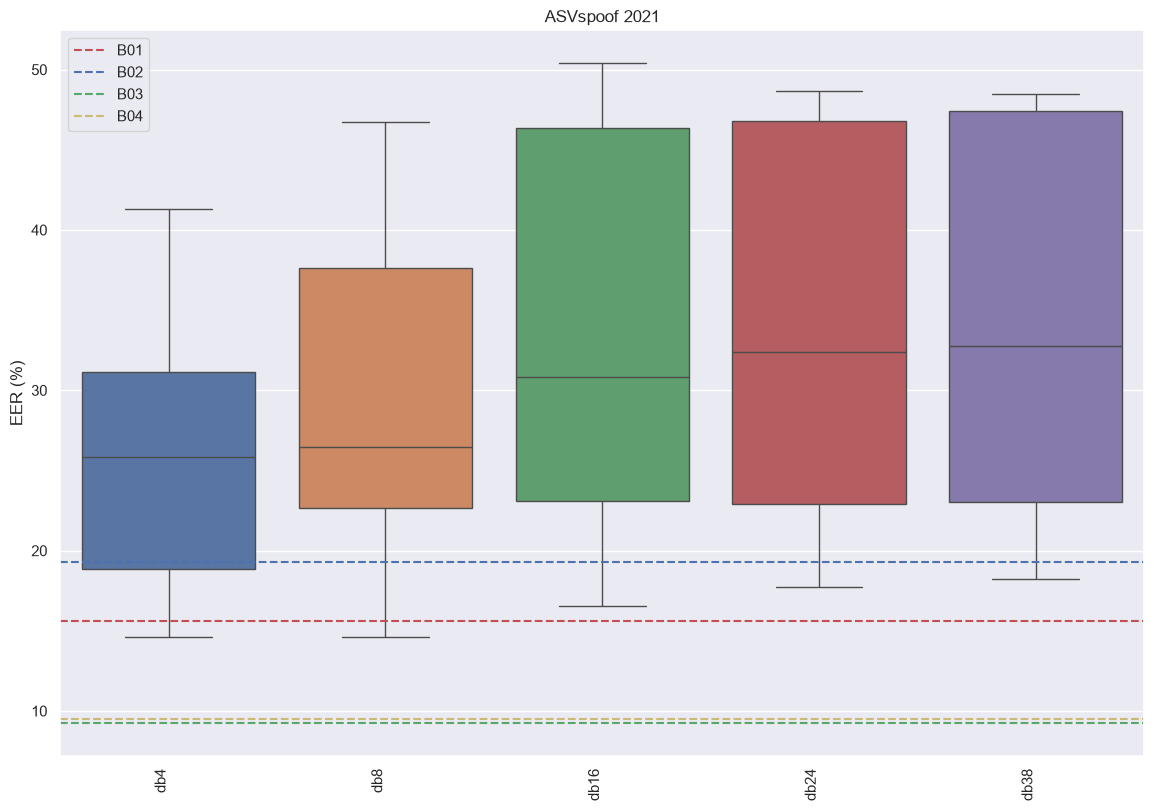

In [221]:
sns.set_theme(rc={'figure.figsize':(11.7,8.27)})
sns.boxplot(data=mean_eer_wave_2021.T)
plt.title("ASVspoof 2021")

baseline_b03 = 9.26
baseline_b04 = 9.50
baseline_b01 = 15.62
baseline_b02 = 19.30

plt.axhline(baseline_b01, color="r", linestyle="--", label="B01")
plt.axhline(baseline_b02, color="b", linestyle="--", label="B02")
plt.axhline(baseline_b03, color="g", linestyle="--", label="B03")
plt.axhline(baseline_b04, color="y", linestyle="--", label="B04")

plt.xticks(rotation=90, ha='right')

plt.xlabel("")
plt.ylabel("EER (%)")
plt.tight_layout()
plt.legend(loc="upper left")
plt.show()

In [222]:
result_2021_wavelet = autorank(mean_eer_wave_2021.T, alpha=0.05, verbose=False,
                       order='ascending', force_mode='nonparametric',
                       effect_size='akinshin_gamma')
print(result_2021_wavelet)

Tests for normality and homoscedacity are ignored for test selection, forcing nonparametric tests
      meanrank     median        mad   ci_lower   ci_upper effect_size  \
db4      1.000  25.854332   7.207258  15.063193  37.105425         0.0   
db8      2.250  26.480364   9.445779  15.565139  42.576574    -0.05026   
db16     3.625  30.828446  12.481121  16.535944  49.989137   -0.329204   
db24     3.625  32.358303  13.725356  16.858072  50.288173   -0.400189   
db38     4.500  32.773755   13.98272  17.193868  50.532786   -0.419573   

       magnitude effect_size_above magnitude_above  
db4   negligible               0.0      negligible  
db8   negligible          -0.05026      negligible  
db16       small         -0.264975           small  
db24       small         -0.078661      negligible  
db38       small         -0.020226      negligible  
RankResult(rankdf=
      meanrank     median        mad   ci_lower   ci_upper effect_size  \
db4      1.000  25.854332   7.207258  15.06319

In [223]:
summary_2021_wavelet = pd.DataFrame({
    "Mean EER": mean_eer_wave_2021.T.mean(),
    "Std EER": mean_eer_wave_2021.T.std(ddof=1),
    "Mean t-DCF": df_2021.groupby("wavelet")["min_tdcf"].mean(),
    "Mean Rank": result_2021_wavelet.rankdf["meanrank"]
})

summary_2021_wavelet = summary_2021_wavelet.sort_values("Mean Rank")

print(summary_2021_wavelet)

       Mean EER    Std EER  Mean t-DCF  Mean Rank
db4   26.084309   8.907722    0.677338      1.000
db8   29.070856  10.915879    0.723368      2.250
db16  33.262541  13.519127    0.779755      3.625
db24  33.573123  13.509795    0.785929      3.625
db38  33.863327  13.472946    0.785853      4.500


In [224]:
create_report(result_2021_wavelet)

The statistical analysis was conducted for 5 populations with 8 paired samples.
The family-wise significance level of the tests is alpha=0.050.
We failed to reject the null hypothesis that the population is normal for all populations (minimal observed p-value=0.048). Therefore, we assume that all populations are normal.
We applied Bartlett's test for homogeneity and failed to reject the null hypothesis (p=0.797) that the data is homoscedastic. Thus, we assume that our data is homoscedastic.
Because we have more than two populations and all populations are normal and homoscedastic, we should use repeated measures ANOVA as omnibus test to determine if there are any significant differences between the mean values of the populations. However, the user decided to force the use of the less powerful Friedman test as omnibus test to determine if there are any significant differences between the mean values of the populations. We report the mean value (M), the standard deviation (SD) and the me

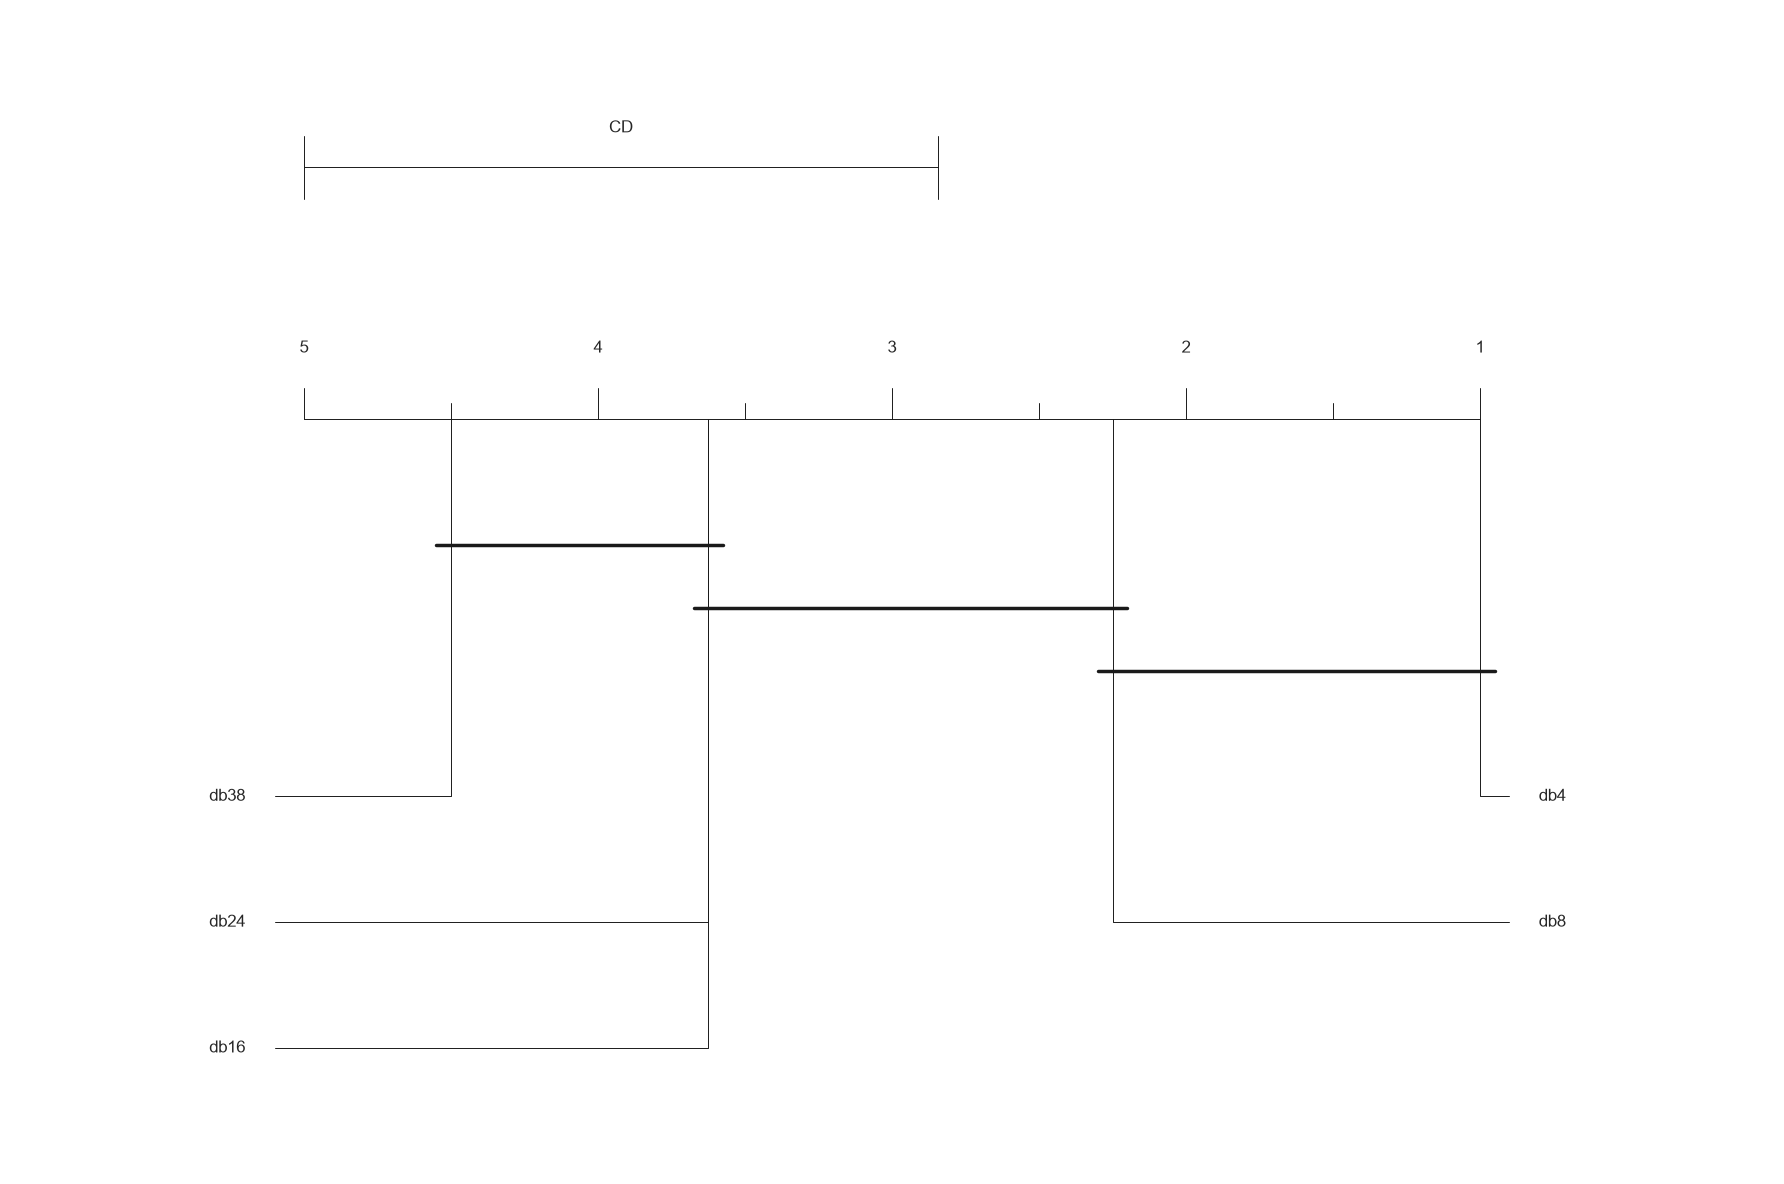

In [225]:
fig, ax = plt.subplots(figsize=(18, 12))

plot_stats(
    result_2021_wavelet,
    allow_insignificant=True,
    ax=ax
)

plt.tight_layout()
plt.show()

### Nodes

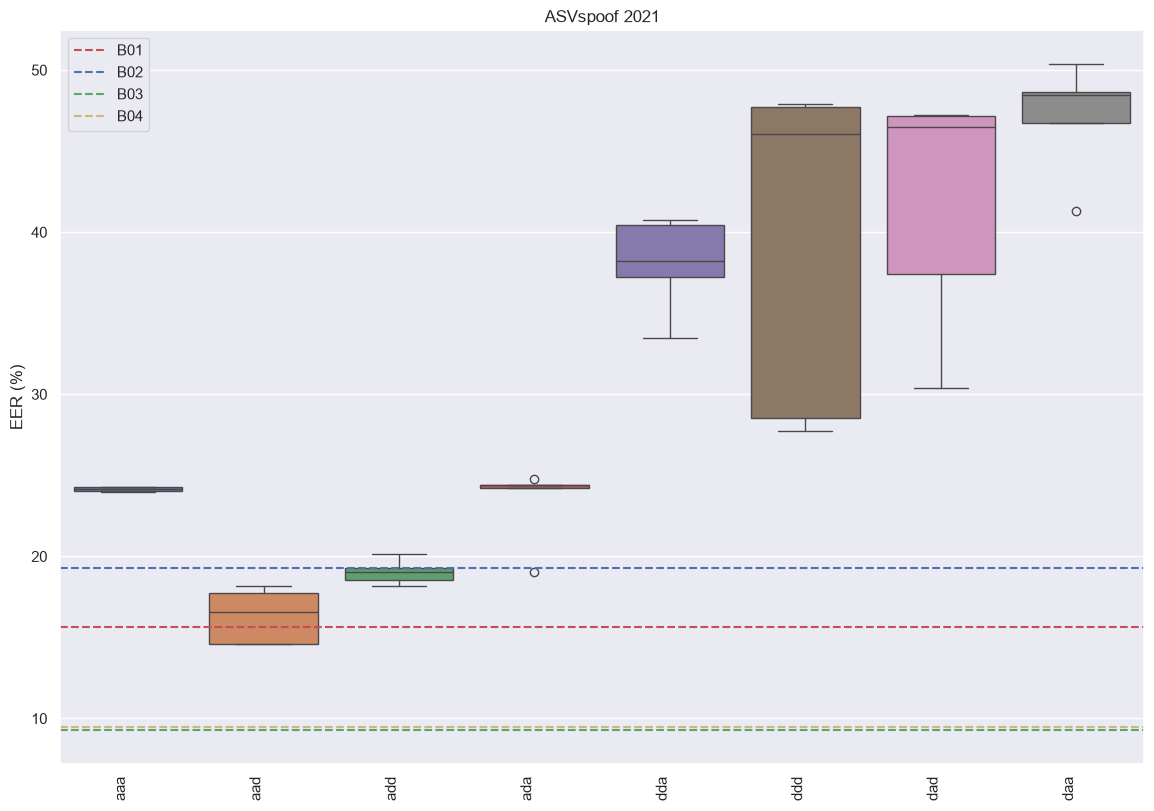

In [226]:
sns.set_theme(rc={'figure.figsize':(11.7,8.27)})
sns.boxplot(data=mean_eer_wave_2021)
plt.title("ASVspoof 2021")

baseline_b03 = 9.26
baseline_b04 = 9.50
baseline_b01 = 15.62
baseline_b02 = 19.30

plt.axhline(baseline_b01, color="r", linestyle="--", label="B01")
plt.axhline(baseline_b02, color="b", linestyle="--", label="B02")
plt.axhline(baseline_b03, color="g", linestyle="--", label="B03")
plt.axhline(baseline_b04, color="y", linestyle="--", label="B04")

plt.xticks(rotation=90, ha='right')

plt.xlabel("")
plt.ylabel("EER (%)")
plt.tight_layout()
plt.legend(loc="upper left")
plt.show()

In [227]:
result_2021_nodes = autorank(mean_eer_wave_2021, alpha=0.05, verbose=False,
                       order='ascending', force_mode='nonparametric',
                       effect_size='akinshin_gamma')
print(result_2021_nodes)

Tests for normality and homoscedacity are ignored for test selection, forcing nonparametric tests
     meanrank     median       mad   ci_lower   ci_upper effect_size  \
aad       1.0  16.576846  1.622874  14.585125   18.19972         0.0   
add       2.0  19.036338  0.488726   18.18587  20.117804   -1.384207   
aaa       3.4  24.125194  0.125828  23.945539  24.296467   -4.423405   
ada       3.6  24.399450  0.196428  19.059183  24.784161   -4.564566   
dda       5.8  38.233564  2.186575    33.4737  40.763349   -7.586353   
ddd       6.0  46.070989  1.849978  27.763124  47.920967  -11.432177   
dad       6.2  46.487049  0.752412  30.377842  47.239461   -15.94946   
daa       8.0  48.473914  1.727011  41.284089  50.384588  -12.838583   

      magnitude effect_size_above magnitude_above  
aad  negligible               0.0      negligible  
add       large         -1.384207           large  
aaa       large         -9.618541           large  
ada       large         -1.121451           l

In [228]:
summary_2021_nodes = pd.DataFrame({
    "Mean EER": mean_eer_wave_2021.mean(),
    "Std EER": mean_eer_wave_2021.std(ddof=1),
    "Mean t-DCF": df_2021.groupby("node")["min_tdcf"].mean(),
    "Mean Rank": result_2021_nodes.rankdf["meanrank"]
})

summary_2021_nodes = summary_2021_nodes.sort_values("Mean Rank")

print(summary_2021_nodes)

      Mean EER    Std EER  Mean t-DCF  Mean Rank
aad  16.339983   1.704209    0.457798        1.0
add  19.032329   0.739617    0.550130        2.0
aaa  24.132705   0.144520    0.628026        3.4
ada  23.372297   2.420232    0.674759        3.6
dda  38.026394   2.941402    0.932837        5.8
ddd  39.610841  10.479756    0.880344        6.0
dad  41.742307   7.580198    0.907290        6.2
daa  47.109792   3.502039    0.972404        8.0


In [231]:
create_report(result_2021_nodes)

The statistical analysis was conducted for 8 populations with 5 paired samples.
The family-wise significance level of the tests is alpha=0.050.
We rejected the null hypothesis that the population is normal for the population ada (p=0.002). Therefore, we assume that not all populations are normal.
Because we have more than two populations and the populations and one of them is not normal, we use the non-parametric Friedman test as omnibus test to determine if there are any significant differences between the median values of the populations. We use the post-hoc Nemenyi test to infer which differences are significant. We report the median (MD), the median absolute deviation (MAD) and the mean rank (MR) among all populations over the samples. Differences between populations are significant, if the difference of the mean rank is greater than the critical distance CD=4.695 of the Nemenyi test.
We reject the null hypothesis (p=0.000) of the Friedman test that there is no difference in the ce

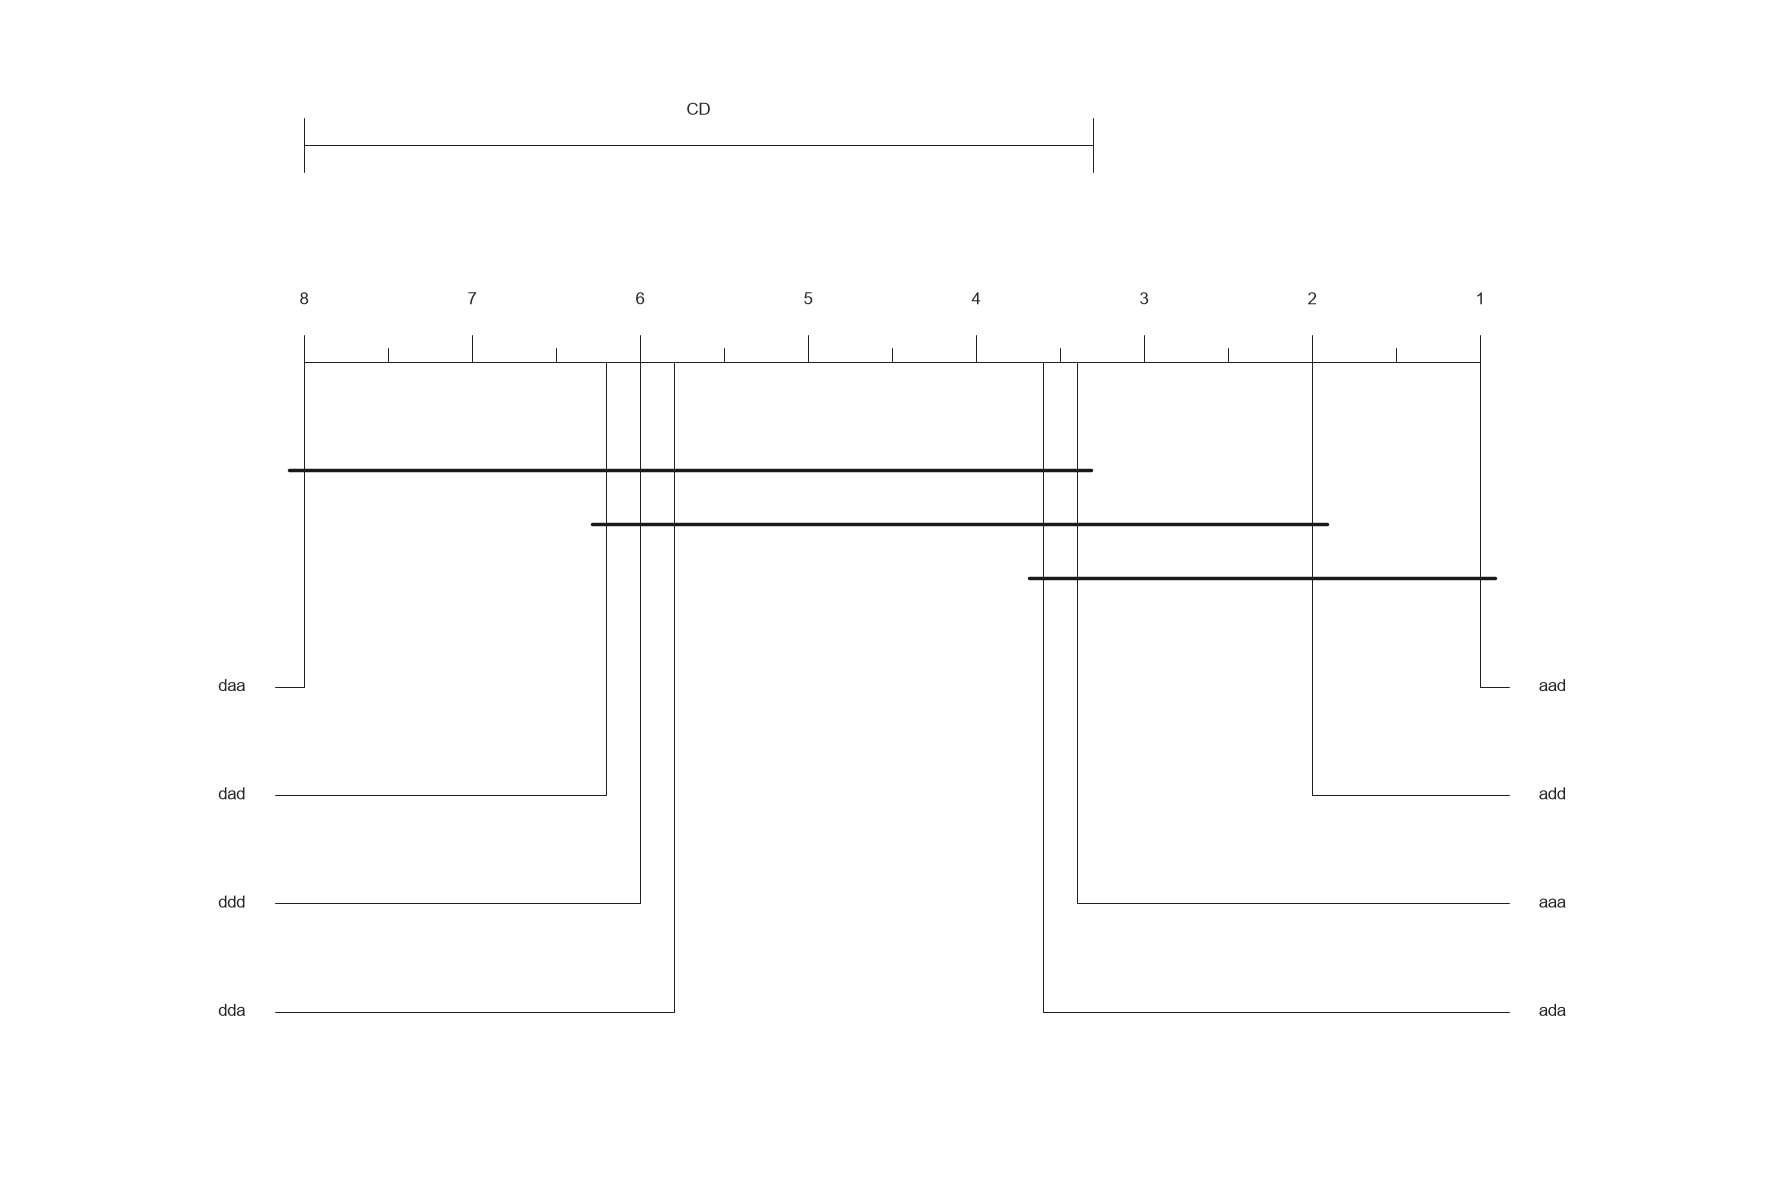

In [232]:
fig, ax = plt.subplots(figsize=(18, 12))

plot_stats(
    result_2021_nodes,
    allow_insignificant=True,
    ax=ax
)

plt.tight_layout()
plt.show()

## Plots

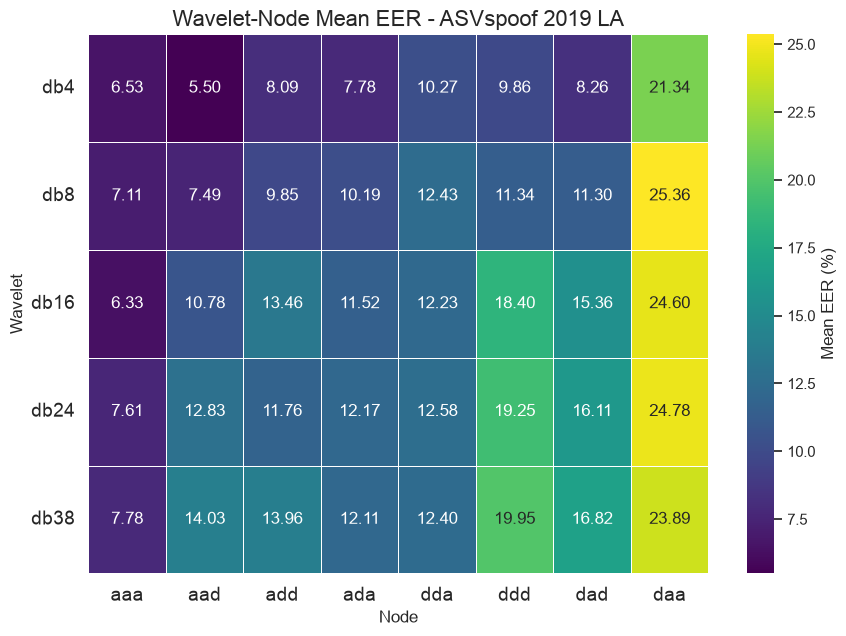

In [115]:
df = autorank_input_2019.copy()

df = df.loc[:, ~df.columns.isin(["max", "average"])]

df.columns = pd.MultiIndex.from_tuples(
    [col.split("_", 1) for col in df.columns],
    names=["Wavelet", "Node"]
)

mean_eer = df.mean(axis=0).unstack("Node")
mean_eer = mean_eer[['aaa', 'aad', 'add', 'ada', 'dda', 'ddd', 'dad', 'daa']]

mean_eer = mean_eer.sort_index(
    key=lambda idx: idx.map(lambda x: int(x.replace("db", "")))
)

fig, ax = plt.subplots(figsize=(10, 7))

sns.heatmap(
    mean_eer,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    linewidths=.5,
    cbar_kws={"label": "Mean EER (%)"},
    ax=ax
)

ax.set_title("Wavelet-Node Mean EER - ASVspoof 2019 LA", fontsize=16)

# Aumentar fontes dos eixos X e Y
ax.tick_params(axis="x", labelsize=14)
ax.tick_params(axis="y", labelsize=14)

# Rotação dos labels
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.show()

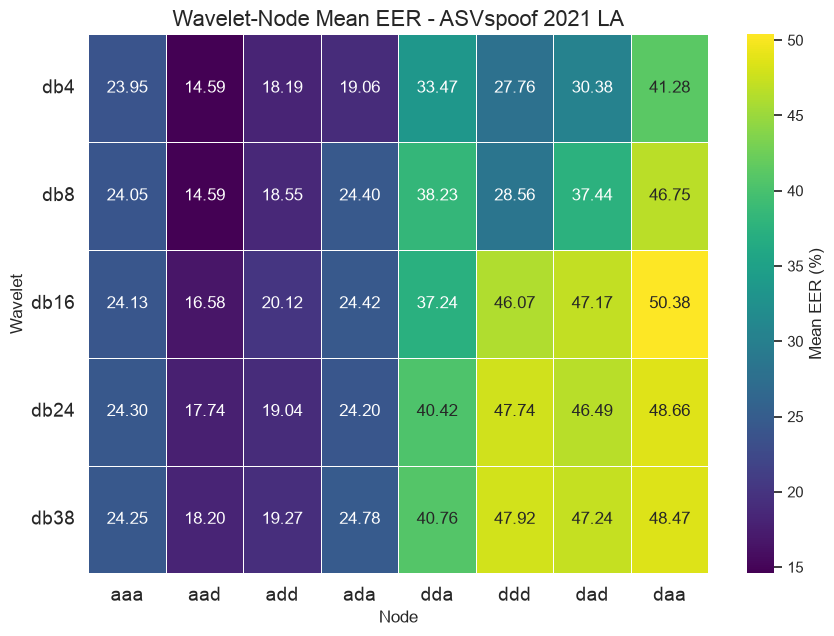

In [116]:
df_2021 = autorank_input_2021.copy()

df_2021 = df_2021.loc[:, ~df_2021.columns.isin(["max", "average"])]

df_2021.columns = pd.MultiIndex.from_tuples(
    [col.split("_", 1) for col in df_2021.columns],
    names=["Wavelet", "Node"]
)

mean_eer_2021 = df_2021.mean(axis=0).unstack("Node")
mean_eer_2021 = mean_eer_2021[['aaa', 'aad', 'add', 'ada', 'dda', 'ddd', 'dad', 'daa']]

mean_eer_2021 = mean_eer_2021.sort_index(
    key=lambda idx: idx.map(lambda x: int(x.replace("db", "")))
)

fig, ax = plt.subplots(figsize=(10, 7))

sns.heatmap(
    mean_eer_2021,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    linewidths=.5,
    cbar_kws={"label": "Mean EER (%)"},
    ax=ax
)

ax.set_title("Wavelet-Node Mean EER - ASVspoof 2021 LA", fontsize=16)

# Aumentar fontes dos eixos X e Y
ax.tick_params(axis="x", labelsize=14)
ax.tick_params(axis="y", labelsize=14)

# Rotação dos labels
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.show()

In [234]:
for name, heat in [("2019", mean_eer), ("2021", mean_eer_2021)]:
    for node1, node2 in combinations(nodes, 2):
        res = wilcoxon(heat[node1], heat[node2])
        print(f"{node1} x {node2} -- {name}: W = {res.statistic}, p = {res.pvalue:.4f}")
    print()

aaa x aad -- 2019: W = 2.0, p = 0.1875
aaa x add -- 2019: W = 0.0, p = 0.0625
aaa x ada -- 2019: W = 0.0, p = 0.0625
aaa x dda -- 2019: W = 0.0, p = 0.0625
aaa x ddd -- 2019: W = 0.0, p = 0.0625
aaa x dad -- 2019: W = 0.0, p = 0.0625
aaa x daa -- 2019: W = 0.0, p = 0.0625
aad x add -- 2019: W = 3.0, p = 0.3125
aad x ada -- 2019: W = 4.0, p = 0.4375
aad x dda -- 2019: W = 4.0, p = 0.4375
aad x ddd -- 2019: W = 0.0, p = 0.0625
aad x dad -- 2019: W = 0.0, p = 0.0625
aad x daa -- 2019: W = 0.0, p = 0.0625
add x ada -- 2019: W = 5.0, p = 0.6250
add x dda -- 2019: W = 5.0, p = 0.6250
add x ddd -- 2019: W = 0.0, p = 0.0625
add x dad -- 2019: W = 0.0, p = 0.0625
add x daa -- 2019: W = 0.0, p = 0.0625
ada x dda -- 2019: W = 0.0, p = 0.0625
ada x ddd -- 2019: W = 0.0, p = 0.0625
ada x dad -- 2019: W = 0.0, p = 0.0625
ada x daa -- 2019: W = 0.0, p = 0.0625
dda x ddd -- 2019: W = 3.0, p = 0.3125
dda x dad -- 2019: W = 3.0, p = 0.3125
dda x daa -- 2019: W = 0.0, p = 0.0625
ddd x dad -- 2019: W = 0.

In [233]:
for name, heat in [("2019", mean_eer.T), ("2021", mean_eer_2021.T)]:
    for wave1, wave2 in combinations(WAVELET_FAMILIES, 2):
        res = wilcoxon(heat[wave1], heat[wave2])
        print(f"{wave1} x {wave2} -- {name}: W = {res.statistic}, p = {res.pvalue:.4f}")
    print()

db4 x db8 -- 2019: W = 0.0, p = 0.0078
db4 x db16 -- 2019: W = 1.0, p = 0.0156
db4 x db24 -- 2019: W = 0.0, p = 0.0078
db4 x db38 -- 2019: W = 0.0, p = 0.0078
db8 x db16 -- 2019: W = 6.0, p = 0.1094
db8 x db24 -- 2019: W = 3.0, p = 0.0391
db8 x db38 -- 2019: W = 4.0, p = 0.0547
db16 x db24 -- 2019: W = 7.0, p = 0.1484
db16 x db38 -- 2019: W = 4.0, p = 0.0547
db24 x db38 -- 2019: W = 10.0, p = 0.3125

db4 x db8 -- 2021: W = 0.0, p = 0.0078
db4 x db16 -- 2021: W = 0.0, p = 0.0078
db4 x db24 -- 2021: W = 0.0, p = 0.0078
db4 x db38 -- 2021: W = 0.0, p = 0.0078
db8 x db16 -- 2021: W = 3.0, p = 0.0391
db8 x db24 -- 2021: W = 1.0, p = 0.0156
db8 x db38 -- 2021: W = 0.0, p = 0.0078
db16 x db24 -- 2021: W = 16.0, p = 0.8438
db16 x db38 -- 2021: W = 11.0, p = 0.3828
db24 x db38 -- 2021: W = 4.0, p = 0.0547



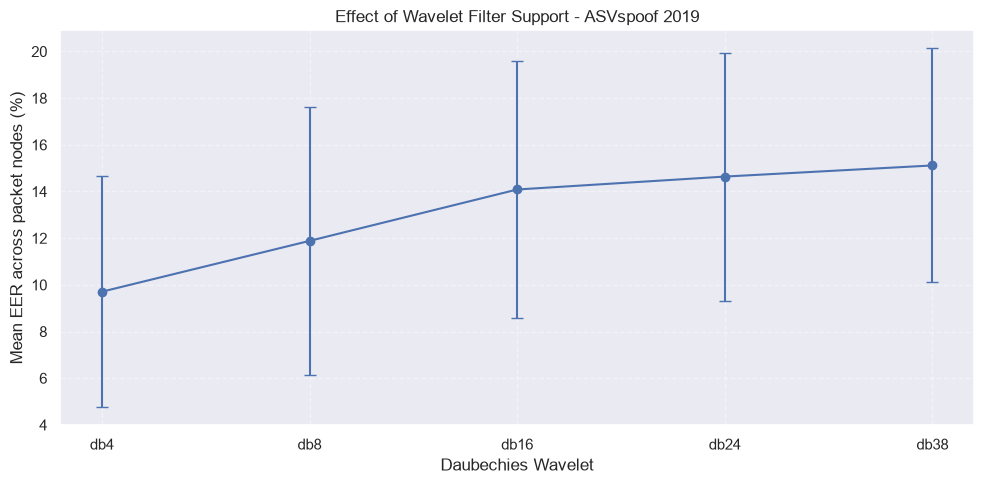

In [45]:
filter_mean = mean_eer.mean(axis=1)
filter_std = mean_eer.std(axis=1)

fig, ax = plt.subplots(figsize=(10, 5))

ax.errorbar(
    filter_mean.index,
    filter_mean.values,
    yerr=filter_std.values,
    marker="o",
    capsize=4,
    linewidth=1.5
)

ax.set_xlabel("Daubechies Wavelet")
ax.set_ylabel("Mean EER across packet nodes (%)")
ax.set_title("Effect of Wavelet Filter Support - ASVspoof 2019")
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

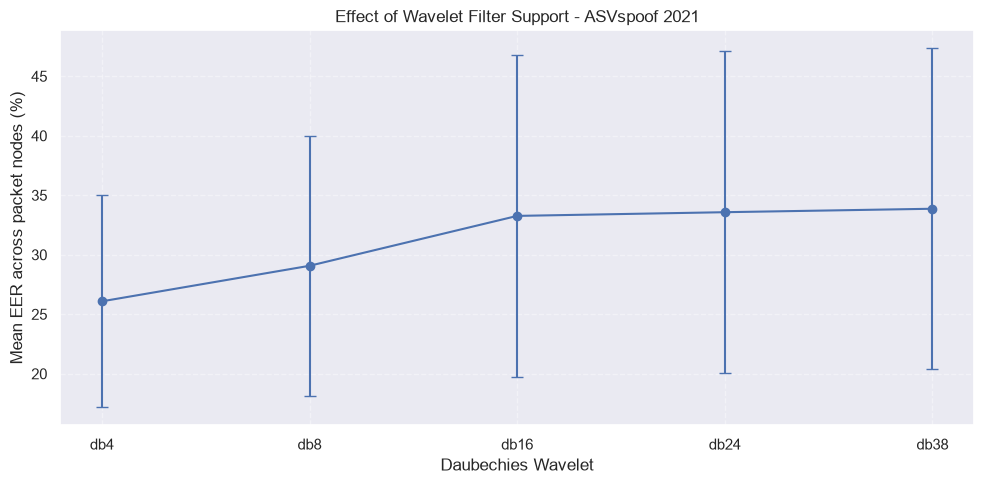

In [46]:
filter_mean_2021 = mean_eer_2021.mean(axis=1)
filter_std_2021 = mean_eer_2021.std(axis=1)

fig, ax = plt.subplots(figsize=(10, 5))

ax.errorbar(
    filter_mean_2021.index,
    filter_mean_2021.values,
    yerr=filter_std_2021.values,
    marker="o",
    capsize=4,
    linewidth=1.5
)

ax.set_xlabel("Daubechies Wavelet")
ax.set_ylabel("Mean EER across packet nodes (%)")
ax.set_title("Effect of Wavelet Filter Support - ASVspoof 2021")
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

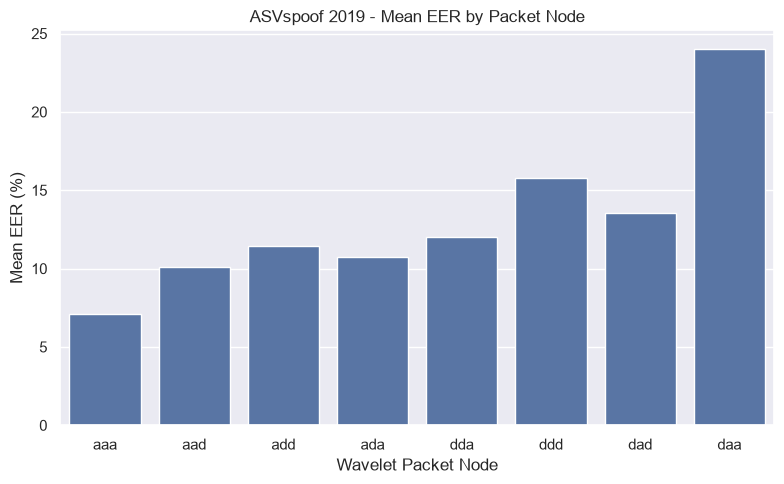

In [125]:
node_mean = mean_eer.mean(axis=0)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=node_mean.index,
    y=node_mean.values,
)

plt.xlabel("Wavelet Packet Node")
plt.ylabel("Mean EER (%)")
plt.title("ASVspoof 2019 - Mean EER by Packet Node")

plt.tight_layout()
plt.show()

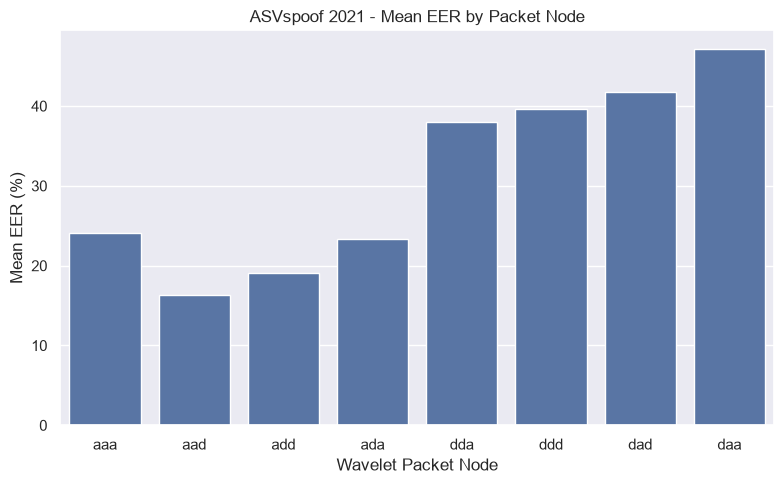

In [124]:
node_mean_2021 = mean_eer_2021.mean(axis=0)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=node_mean_2021.index,
    y=node_mean_2021.values
)

plt.xlabel("Wavelet Packet Node")
plt.ylabel("Mean EER (%)")
plt.title("ASVspoof 2021 - Mean EER by Packet Node")

plt.tight_layout()
plt.show()